# EMPLOYEE SALARY PREDICTION

## Project Overview

In [ ]:
# ============================================================
# PROJECT: Medical Insurance Cost Prediction
# ============================================================
#
# Dataset: Medical Cost Personal Datasets
# Data Source: Kaggle
# Data URL: https://www.kaggle.com/datasets/mirichoi0218/insurance
# Dataset File: medical_insurance_cost_prediction_raw.csv
# Task: Regression
# Target Variable: charges
#
# Objective:
# Predict individual medical insurance charges using
# regression algorithms while implementing an end-to-end
# machine learning workflow from raw data to model prediction.
#
# Description:
# End-to-end regression project covering data auditing,
# cleaning, exploratory data analysis, feature engineering,
# transformation, categorical encoding, preprocessing,
# feature selection, multicollinearity analysis, model
# training, hyperparameter tuning, cross-validation, residual
# analysis, visualization, error handling, model persistence,
# and prediction.
#
# Repository Description:
# Machine learning project for predicting individual medical
# insurance charges using regression models, Python,
# scikit-learn, and the Medical Cost Personal Datasets.
#
# Model: Regression Models
# Framework: Scikit-learn
# Dependencies: Python, Pandas, NumPy, Matplotlib, Seaborn,
#               Scikit-learn, Statsmodels, SciPy
#
# Evaluation Metrics: MAE, MSE, RMSE, R²
#
# Project Stage: Development
#
# Python Version: 3.12
#
# Version: 1.0.0
# Version Label: Initial Development
#
# Date Started: 2026-10-24
# Last Updated: 2026-10-24
#
# Author: Samuel Ablordeppey
# ============================================================

## Imports

In [4]:
# Standard library
from pathlib import Path
import sys
from IPython.display import display

# Data manipulation
import numpy as np
import pandas as pd
import data_profiling

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistics
import scipy.stats as stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Machine learning
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.compose import make_column_selector

from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib


from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

## Environment & Reproducibility

In [5]:
# Python Version
print(f"Python: {sys.version}")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

# visualization settings.
plt.rcParams["figure.figsize"] = (10, 6)
plt.style.use("seaborn-v0_8-whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 300

Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


## Configurations

### Project Paths

In [66]:
# Project Paths
BASE_DIR = Path.cwd().parent

NOTEBOOKS_DIR = BASE_DIR / "notebooks"

DATA_DIR = BASE_DIR / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"

OUTPUT_DIR = BASE_DIR / "outputs"
TABLES_DIR = OUTPUT_DIR / "tables"
FIGURES_DIR = OUTPUT_DIR / "figures"

MODEL_DIR = BASE_DIR / "models"

### File Paths

In [67]:
RAW_DATA_FILE = RAW_DATA_DIR / "data_science_salary_raw.csv"

### Machine Learning Config

In [68]:
# ============================================================
# TARGET CONFIGURATION
# ============================================================
TARGET_COLUMN = "salary_in_usd"
TARGET_COLUMN_NAME = {
    "label": "Data Science Salary",
    "feature": "Salary In USD",
}
EXCLUDE_COLUMNS = []


# ============================================================
# MACHINE LEARNING CONFIGURATION
# ============================================================
TEST_SIZE = 0.20
RANDOM_STATE = 42

# ============================================================
# EVALUATION CONFIGURATION
# ============================================================
CROSS_VALIDATION_FOLDS = 5

# ============================================================
# PREPROCESSING CONFIGURATION
# ============================================================
NUMERICAL_IMPUTATION = "median"
CATEGORICAL_IMPUTATION = "most_frequent"

# ============================================================
# FEATURE ENGINEERING CONFIGURATION
# ============================================================
FEATURES_TO_CREATE = []

# ============================================================
# FEATURE SELECTION CONFIGURATION
# ============================================================
CORRELATION_THRESHOLD = 0.80
VIF_THRESHOLD = 5

### Model Configuration

In [69]:
REGRESSION_MODEL_CONFIG = {
    "Linear Regression": {
        "estimator": LinearRegression(),
        "baseline": True,
        "param_grid": {
            "model__fit_intercept": [True, False]
        }, 
        "model_diagnostics": [
            "residuals_vs_predicted",
            "residual_distribution",
            "normal_qq_plot",
            "residuals_vs_actual",
            "actual_vs_predicted"
        ]
    },

    "Ridge": {
        "estimator": Ridge(),
        "baseline": False,
        "param_grid": {
            "model__alpha": [0.1, 1.0, 10.0, 100.0]
        },
        "model_diagnostics": [
            "residuals_vs_predicted",
            "residual_distribution",
            "normal_qq_plot",
            "residuals_vs_actual",
            "actual_vs_predicted"
        ]
    },

    "Lasso": {
        "estimator": Lasso(),
        "baseline": False,
        "param_grid": {
            "model__alpha": [1.0, 10.0, 100.0],
            "model__max_iter": [20000]
        },
        "model_diagnostics": [
            "residuals_vs_predicted",
            "residual_distribution",
            "normal_qq_plot",
            "residuals_vs_actual",
            "actual_vs_predicted"
        ]
    },

    "Elastic Net": {
        "estimator": ElasticNet(),
        "baseline": False,
        "param_grid": {
            "model__alpha": [0.1, 1.0, 10.0],
            "model__l1_ratio": [0.2, 0.5, 0.8],
            "model__max_iter": [20000]
        },
        "model_diagnostics": [
            "residuals_vs_predicted",
            "residual_distribution",
            "normal_qq_plot",
            "residuals_vs_actual",
            "actual_vs_predicted"
        ]
    },

    "Random Forest": {
        "estimator": RandomForestRegressor(random_state=RANDOM_STATE),
        "baseline": False,
        "param_grid": {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 10, 20],
            "model__min_samples_leaf": [1, 2]
        },
        "model_diagnostics": [
            "residuals_vs_predicted",
            "residual_distribution",
            "normal_qq_plot",
            "residuals_vs_actual",
            "actual_vs_predicted"
        ]
    },

    "Gradient Boosting": {
        "estimator": GradientBoostingRegressor(
            random_state=RANDOM_STATE
        ),
        "baseline": False,
        "param_grid": {
            "model__n_estimators": [100, 200],
            "model__learning_rate": [0.03, 0.1],
            "model__max_depth": [2, 3, 4]
        },
        "model_diagnostics": [
            "residuals_vs_predicted",
            "residual_distribution",
            "normal_qq_plot",
            "residuals_vs_actual",
            "actual_vs_predicted"
        ]
    },

    "KNN": {
        "estimator": KNeighborsRegressor(),
        "baseline": False,
        "param_grid": {
            "model__n_neighbors": [3, 5, 7, 11],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        },
        "model_diagnostics": [
            "residuals_vs_predicted",
            "residual_distribution",
            "normal_qq_plot",
            "residuals_vs_actual",
            "actual_vs_predicted"
        ]
    },

    # "SVR": {
    #     "estimator": SVR(),
    #     "baseline": False,
    #     "param_grid": {
    #         "model__C": [1, 10, 100],
    #         "model__epsilon": [0.1, 0.2],
    #         "model__kernel": ["linear", "rbf"]
    #     },
    #     "model_diagnostics": [
    #         "residuals_vs_predicted",
    #         "residual_distribution",
    #         "normal_qq_plot",
    #         "residuals_vs_actual",
    #         "actual_vs_predicted"
    #     ]
    # }
}



# ============================================================
# DERIVE EXISTING VARIABLES AUTOMATICALLY
# ============================================================

BASELINE_MODEL_NAME = next(
    name
    for name, config in REGRESSION_MODEL_CONFIG.items()
    if config["baseline"]
)

BASELINE_MODEL = clone(
    REGRESSION_MODEL_CONFIG[BASELINE_MODEL_NAME]["estimator"]
)

### Metrics Configuration

In [70]:
# ============================================================
# METRICS CONFIGURATION
# ============================================================
PREFERRED_METRICS_COLUMNS = [
    "Model",
    "Initial CV RMSE",
    "Initial CV RMSE Std",
    "Initial Test RMSE",
    "Initial Test MAE",
    "Initial Test R2",
    "Tuned CV RMSE",
    "Tuned Test RMSE",
    "Tuned Test MAE",
    "Tuned Test R2",
    "Best Parameters"
]


def calculate_rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


REGRESSION_METRICS = {

    "RMSE": {
        "label": "Root Mean Squared Error",
        "scoring": "neg_root_mean_squared_error",
        "direction": "minimize",
        "column": "RMSE",
        "calculate": calculate_rmse,
        "comparison_columns": {
            "initial_test": "Initial Test RMSE",
            "initial_cv": "Initial CV RMSE",
            "tuned_cv": "Tuned CV RMSE",
            "final_test": "Tuned Test RMSE"
        }
    },

    "MAE": {
        "label": "Mean Absolute Error",
        "scoring": "neg_mean_absolute_error",
        "direction": "minimize",
        "column": "MAE",
        "calculate": mean_absolute_error,
        "comparison_columns": {
            "initial_test": "Initial Test MAE",
            "final_test": "Tuned Test MAE"
        }
    },

    "R2": {
        "label": "Coefficient of Determination",
        "scoring": "r2",
        "direction": "maximize",
        "column": "R2",
        "calculate": r2_score,
        "comparison_columns": {
            "initial_test": "Initial Test R2",
            "final_test": "Tuned Test R2"
        }
    },

    "CV_MEAN_RMSE": {
        "label": "Mean Cross-Validation RMSE",
        "scoring": "neg_root_mean_squared_error",
        "source_metric": "RMSE",
        "direction": "minimize",
        "column": "CV_Mean_RMSE",
        "result_columns": {
            "baseline": "CV_Mean_RMSE",
            "initial_cv": "Mean CV RMSE",
            "tuned_cv": "Best CV RMSE"
        }
    },

    "CV_RMSE_STD": {
        "label": "Cross-Validation RMSE Standard Deviation",
        "scoring": None,
        "source_metric": "RMSE",
        "direction": "minimize",
        "column": "CV_RMSE_Std",
        "result_columns": {
            "baseline": "CV_RMSE_Std",
            "initial_cv": "Std CV RMSE"
        }
    }
}


# ============================================================
# DERIVE THE DEFAULT SCORING METRIC
# ============================================================
SCORING_METRIC = REGRESSION_METRICS["RMSE"]["scoring"]

## Helper Functions

### Save

In [71]:
# ============================================================
# HELPER FUNCTIONS: SAVE DATA, TABLES, AND FIGURES
# ============================================================

def save_data(data, filename, directory=PROCESSED_DATA_DIR, index=True):
    """Save a pandas DataFrame as a CSV file."""
    directory.mkdir(parents=True, exist_ok=True)

    file_path = directory / filename

    if file_path.suffix.lower() != ".csv":
        file_path = file_path.with_suffix(".csv")

    data.to_csv(file_path, index=index)

    print(f"Data saved to: {file_path}")

    return file_path


def save_table(table, filename, directory=TABLES_DIR, index=True):
    """Save a pandas DataFrame as a CSV file."""
    directory.mkdir(parents=True, exist_ok=True)

    file_path = directory / filename

    if file_path.suffix.lower() != ".csv":
        file_path = file_path.with_suffix(".csv")

    table.to_csv(file_path, index=index)

    print(f"Table saved to: {file_path}")

    return file_path


def save_figure(filename, directory=FIGURES_DIR, fig=None, dpi=300):
    """Save a Matplotlib figure as a PNG file."""
    import matplotlib.pyplot as plt

    directory.mkdir(parents=True, exist_ok=True)

    file_path = directory / filename

    if file_path.suffix.lower() != ".png":
        file_path = file_path.with_suffix(".png")

    if fig is None:
        fig = plt.gcf()

    fig.savefig(file_path, dpi=dpi, bbox_inches="tight")

    print(f"Figure saved to: {file_path}")

    return file_path

### Utils

In [72]:
def get_feature_types(df, exclude=None):
    """
    Return numerical and categorical column names,
    excluding specified columns.
    """

    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    if exclude is not None and not isinstance(exclude, (list, tuple, set)):
        raise TypeError("exclude must be a list, tuple, set, or None.")

    exclude = set(exclude or [])

    numerical = [
        col for col in df.select_dtypes(include="number").columns
        if col not in exclude
    ]

    categorical = [
        col for col in df.select_dtypes(
            include=["object", "category", "bool", "string"]
        ).columns
        if col not in exclude
    ]

    return numerical, categorical


def normalize_missing_values(X):
    """
    Normalize missing values by converting pandas missing-value markers
    to NumPy NaN for compatibility with scikit-learn preprocessing.
    """
    X = np.asarray(X, dtype=object)
    X[pd.isna(X)] = np.nan
    return X

## Data Loading

In [110]:
df_raw = pd.read_csv(RAW_DATA_FILE)

## Initial Data Inspection

### Inspect Data

In [111]:
def inspect(df):
    """
    Return basic information about the dataset.
    """
    print("Shape:", df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nInfo:")
    display(df.info(5))

inspect(df_raw)

Shape: (3755, 7)

Columns:
['work_year', 'experience_level', 'employment_type', 'job_title', 'salary_in_usd', 'company_location', 'company_size']

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3755 entries, 0 to 3754
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   work_year         3755 non-null   int64 
 1   experience_level  3755 non-null   object
 2   employment_type   3755 non-null   object
 3   job_title         3755 non-null   object
 4   salary_in_usd     3755 non-null   int64 
 5   company_location  3755 non-null   object
 6   company_size      3755 non-null   object
dtypes: int64(2), object(5)
memory usage: 205.5+ KB


None

### Preview Data

In [112]:
def preview(df, n=5, random_state=RANDOM_STATE):
    """
    Display head, tail, and random sample.
    """
    print("Head:")
    display(df.head(n))

    print("\nTail:")
    display(df.tail(n))

    print("\nRandom Sample:")
    display(
        df.sample(
            min(n, len(df)),
            random_state=random_state
        )
    )

preview(df_raw, n=5, random_state=RANDOM_STATE)

Head:


,work_year,experience_level,employment_type,job_title,salary_in_usd,company_location,company_size
0,2023,Senior-level,Full-time,Principal Data Scientist,85847,ES,Large
1,2023,Mid-level,Contract,ML Engineer,30000,US,Small
2,2023,Mid-level,Contract,ML Engineer,25500,US,Small
3,2023,Senior-level,Full-time,Data Scientist,175000,CA,Medium
4,2023,Senior-level,Full-time,Data Scientist,120000,CA,Medium



Tail:


,work_year,experience_level,employment_type,job_title,salary_in_usd,company_location,company_size
3750,2020,Senior-level,Full-time,Data Scientist,412000,US,Large
3751,2021,Mid-level,Full-time,Principal Data Scientist,151000,US,Large
3752,2020,Entry-level,Full-time,Data Scientist,105000,US,Small
3753,2020,Entry-level,Contract,Business Data Analyst,100000,US,Large
3754,2021,Senior-level,Full-time,Data Science Manager,94665,IN,Large



Random Sample:


,work_year,experience_level,employment_type,job_title,salary_in_usd,company_location,company_size
2148,2022,Senior-level,Full-time,Machine Learning Software Engineer,168000,CA,Medium
1044,2023,Senior-level,Full-time,Data Analyst,179975,US,Medium
3321,2022,Senior-level,Full-time,Data Scientist,144000,US,Medium
439,2023,Senior-level,Full-time,Applied Scientist,222200,US,Large
3519,2021,Executive-level,Full-time,Head of Data,230000,RU,Large


### Describe Data

In [113]:
def describe(df, include=None):
    """
    Generate descriptive statistics.
    """

    print("Data Description: \n")
    display(df.describe(include=include))

def unique_values(df, column):
    """
    Return unique values, number of unique values,
    and value counts for a column.
    """

    dataframe = pd.DataFrame({
        "unique": df[column].unique(),
        "nunique": df[column].nunique(),
        "value_counts": df[column].value_counts()
    })

    display(dataframe)

describe(df_raw, include="all")

Data Description: 



,work_year,experience_level,employment_type,job_title,salary_in_usd,company_location,company_size
count,3755.000000,3755,3755,3755,3755.000000,3755,3755
unique,NaN,4,4,93,NaN,72,3
top,NaN,Senior-level,Full-time,Data Engineer,NaN,US,Medium
freq,NaN,2516,3718,1040,NaN,3040,3153
mean,2022.373635,NaN,NaN,NaN,137570.389880,NaN,NaN
std,0.691448,NaN,NaN,NaN,63055.625278,NaN,NaN
min,2020.000000,NaN,NaN,NaN,5132.000000,NaN,NaN
25%,2022.000000,NaN,NaN,NaN,95000.000000,NaN,NaN
50%,2022.000000,NaN,NaN,NaN,135000.000000,NaN,NaN
75%,2023.000000,NaN,NaN,NaN,175000.000000,NaN,NaN


### Data Profiling

In [114]:
def data_profiling_report(df, use_sample=True, sample_size=0.5):
    """
    Generate a profiling report using a sample proportion or the full dataset.
    """
    data = (
        df.sample(frac=sample_size, random_state=42)
        if use_sample
        else df
    )

    profile = data_profiling.ProfileReport(
        data,
        title=f"{TARGET_COLUMN_NAME['label']} Prediction Data Profiling Report",
        explorative=True
    )

    filename = f"{TARGET_COLUMN_NAME['label'].replace(" ", "_").lower()}_prediction_data_profiling_report.html"
    report_path = NOTEBOOKS_DIR / filename
    profile.to_file(report_path)


# Use 80% of the dataset
# data_profiling_report(df_raw, sample_size=0.2)

# Use the full dataset
# data_profiling_report(df_raw, use_sample=False)

## Data Preparation & Cleaning

In [115]:
df_clean = df_raw.copy()

### Data Structure and Data Types

In [116]:
# Inpsect Data Structure and Data Types
def data_type_summary(df):
    """
    Return each column's data type and number of missing values.
    """
    return pd.DataFrame({
        "data_type": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "unique_count": df.nunique()
    }).reset_index(names="column")


print("Data Type Summary:") 
display(data_type_summary(df_clean))

Data Type Summary:


,column,data_type,missing_count,unique_count
0,work_year,int64,0,4
1,experience_level,object,0,4
2,employment_type,object,0,4
3,job_title,object,0,93
4,salary_in_usd,int64,0,1035
5,company_location,object,0,72
6,company_size,object,0,3


In [117]:
def handle_data_types(
    df,
    numeric_columns=None,
    categorical_columns=None,
    comma_numeric_columns=None
):
    """
    Convert selected columns to appropriate data types.
    Note: Add only columns that need conversion. 
    """
    df = df.copy()

    numeric_columns = numeric_columns or []
    categorical_columns = categorical_columns or []
    comma_numeric_columns = comma_numeric_columns or []

    for column in comma_numeric_columns:
        df[column] = pd.to_numeric(
            df[column]
            .astype("string")
            .str.replace(",", "", regex=False),
            errors="coerce"
        )

    for column in numeric_columns:
        df[column] = pd.to_numeric(
            df[column],
            errors="coerce"
        )

    for column in categorical_columns:
        df[column] = df[column].astype("category")

    return df

df_clean = handle_data_types(
    df_clean,
    numeric_columns=[],
    categorical_columns=[],
    comma_numeric_columns=[]
)

print("Data Type Summary After Handling Data Types:")
display(data_type_summary(df_clean))
print("\nShape after handling data types:", df_clean.shape)


Data Type Summary After Handling Data Types:


,column,data_type,missing_count,unique_count
0,work_year,int64,0,4
1,experience_level,object,0,4
2,employment_type,object,0,4
3,job_title,object,0,93
4,salary_in_usd,int64,0,1035
5,company_location,object,0,72
6,company_size,object,0,3



Shape after handling data types: (3755, 7)


### Define Numerical and Categorical Features

In [118]:
numerical_features, categorical_features = get_feature_types(df_clean, exclude=[TARGET_COLUMN])

print("Numerical Features:")
describe(df_clean[numerical_features], include="all")

print("\nCategorical Features:")
describe(df_clean[categorical_features], include="all")

Numerical Features:
Data Description: 



,work_year
count,3755.000000
mean,2022.373635
std,0.691448
min,2020.000000
25%,2022.000000
50%,2022.000000
75%,2023.000000
max,2023.000000



Categorical Features:
Data Description: 



,experience_level,employment_type,job_title,company_location,company_size
count,3755,3755,3755,3755,3755
unique,4,4,93,72,3
top,Senior-level,Full-time,Data Engineer,US,Medium
freq,2516,3718,1040,3040,3153


### Validate Target Variable

In [119]:
def target_summary(df, target):
    """
    Print validation details for a regression target.
    """
    if target not in df.columns:
        raise ValueError(f"Target column '{target}' not found.")

    print(f"Target: {target}")
    print(f"Data type: {df[target].dtype}")
    print(f"Missing values: {df[target].isna().sum()}")
    print(f"Unique values: {df[target].nunique()}")
    print(f"Standard deviation: {df[target].std()}")

    print("\nStatistics:")
    display(df[target].describe())

print("Target Summary: \n")
target_summary(df_clean, TARGET_COLUMN)

Target Summary: 

Target: salary_in_usd
Data type: int64
Missing values: 0
Unique values: 1035
Standard deviation: 63055.6252782241

Statistics:


count      3755.000000
mean     137570.389880
std       63055.625278
min        5132.000000
25%       95000.000000
50%      135000.000000
75%      175000.000000
max      450000.000000
Name: salary_in_usd, dtype: float64

In [120]:
def handle_target(df, target=TARGET_COLUMN):
    """
    Validate and clean the regression target.
    """
    if target not in df.columns:
        raise ValueError(f"Target column '{target}' not found.")

    df = df.copy()

    # Remove rows with missing target values
    df = df.dropna(subset=[target])

    # Ensure target is numeric
    df[target] = pd.to_numeric(df[target], errors="coerce")

    # Remove rows that became missing after conversion
    df = df.dropna(subset=[target])

    # Reject invalid negative target values
    df = df[df[target] >= 0]

    return df


df_clean = handle_target(df_clean, target=TARGET_COLUMN)
print("Target Summary After Handling Target: \n")
display(target_summary(df_clean, TARGET_COLUMN))
print("\nShape after handling target:", df_clean.shape)

Target Summary After Handling Target: 

Target: salary_in_usd
Data type: int64
Missing values: 0
Unique values: 1035
Standard deviation: 63055.6252782241

Statistics:


count      3755.000000
mean     137570.389880
std       63055.625278
min        5132.000000
25%       95000.000000
50%      135000.000000
75%      175000.000000
max      450000.000000
Name: salary_in_usd, dtype: float64

None


Shape after handling target: (3755, 7)


### Check and Handle Duplicate

In [121]:
def duplicate_summary(df):
    """
    Return the number and percentage of duplicate rows.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    duplicate_count = df.duplicated().sum()

    return pd.DataFrame({
        "duplicate_count": [duplicate_count],
        "duplicate_percentage": [duplicate_count / len(df) * 100 if len(df) else 0]
    })


duplicate_summary(df_clean)

,duplicate_count,duplicate_percentage
0,1351,35.978695


In [122]:
def handle_duplicates(df, keep="first"):
    """
    Remove duplicate rows.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    if keep not in ("first", "last", False):
        raise ValueError("keep must be 'first', 'last', or False.")

    return df.drop_duplicates(keep=keep).copy()


df_clean = handle_duplicates(df_clean)

print("Duplicate Summary After Handling Duplicates:")
display(duplicate_summary(df_clean))

print("\nShape after handling duplicates:", df_clean.shape)

Duplicate Summary After Handling Duplicates:


,duplicate_count,duplicate_percentage
0,0,0.0



Shape after handling duplicates: (2404, 7)


### Check Data Consistency and Invalid Values

In [123]:
def consistency_summary(df):
    """
    Return data consistency issues for numerical and text columns.
    """
    results = []

    for column in df.columns:
        negative_count = 0
        if pd.api.types.is_numeric_dtype(df[column]):
            negative_count = (df[column] < 0).sum()

        whitespace_count = 0
        if (
            pd.api.types.is_string_dtype(df[column])
            or df[column].dtype == "object"
        ):
            values = df[column].dropna().astype("string")
            whitespace_count = (
                values != values.str.strip()
            ).sum()

        results.append({
            "column": column,
            "negative_count": negative_count,
            "whitespace_count": whitespace_count
        })

    return pd.DataFrame(results)

print("Consistency Summary:")
display(consistency_summary(df_clean))

Consistency Summary:


,column,negative_count,whitespace_count
0,work_year,0,0
1,experience_level,0,0
2,employment_type,0,0
3,job_title,0,0
4,salary_in_usd,0,0
5,company_location,0,0
6,company_size,0,0


In [124]:
def handle_data_consistency(
    df,
    standardize_columns=None,
    datetime_columns=None,
    lowercase=True
):
    """
    Standardize text values and convert selected columns to datetime.
    Note: Negative values and invalid ranges should be checked against each column’s meaning before changing or removing them.
    """
    df = df.copy()

    standardize_columns = standardize_columns or []
    datetime_columns = datetime_columns or []

    for column in standardize_columns:
        df[column] = df[column].astype("string").str.strip()

        if lowercase:
            df[column] = df[column].str.lower()

    for column in datetime_columns:
        df[column] = pd.to_datetime(df[column], errors="coerce")

    return df


df_clean = handle_data_consistency(
    df_clean,
    standardize_columns=categorical_features,
    datetime_columns=[]
)

print("Data Consistency Summary After Handling Data Consistency:")
display(consistency_summary(df_clean))
print("\nShape after handling data consistency:", df_clean.shape)

Data Consistency Summary After Handling Data Consistency:


,column,negative_count,whitespace_count
0,work_year,0,0
1,experience_level,0,0
2,employment_type,0,0
3,job_title,0,0
4,salary_in_usd,0,0
5,company_location,0,0
6,company_size,0,0



Shape after handling data consistency: (2404, 7)


### Missing Value Summary & Handling

In [125]:
def missing_summary(df):
    """
    Return missing value count and percentage.
    """
    return pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percentage": df.isna().mean() * 100
    })

missing_summary(df_raw)

,missing_count,missing_percentage
work_year,0,0.0
experience_level,0,0.0
employment_type,0,0.0
job_title,0,0.0
salary_in_usd,0,0.0
company_location,0,0.0
company_size,0,0.0


**Handle Missing Values: Missing-value imputation is handled by SimpleImputer inside the preprocessing pipeline after the train-test split.**

In [126]:
# Not used: Missing-value imputation is handled by SimpleImputer
# inside the preprocessing pipeline after the train-test split.

# def handle_missing_values(df, numerical_strategy="median", categorical_strategy="most_frequent"):
#     """
#     Handle missing numerical and categorical values.
#     Note: This fills missing values in all numerical and categorical columns. Drop features with extremely high missingness only after investigating them.
#     """
#     df = df.copy()

#     numerical_cols = numerical_features
#     categorical_cols = categorical_features

#     # Numerical variables
#     if numerical_strategy == "median":
#         df[numerical_cols] = df[numerical_cols].fillna(
#             df[numerical_cols].median()
#         )
#     elif numerical_strategy == "mean":
#         df[numerical_cols] = df[numerical_cols].fillna(
#             df[numerical_cols].mean()
#         )
#     else:
#         raise ValueError("numerical_strategy must be 'median' or 'mean'.")

#     # Categorical variables
#     if categorical_strategy == "most_frequent":
#         for col in categorical_cols:
#             if df[col].isna().any() and not df[col].mode().empty:
#                 df[col] = df[col].fillna(df[col].mode().iloc[0])
#     elif categorical_strategy == "unknown":
#         df[categorical_cols] = df[categorical_cols].fillna("Unknown")
#     else:
#         raise ValueError(
#             "categorical_strategy must be 'most_frequent' or 'unknown'."
#         )

#     return df


# df_clean = handle_missing_values(df_raw)
# print("Missing Values Summary:")
# display(missing_summary(df_clean))

# df_clean.shape

### Outlier Summary & Handling

In [127]:
def outlier_summary(df, columns=None, multiplier=1.5):
    """
    Summarize potential outliers using the IQR method.
    """
    if columns is None:
        columns = numerical_features

    summary = []

    for column in columns:
        q1 = df[column].quantile(0.25)
        q3 = df[column].quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - multiplier * iqr
        upper_bound = q3 + multiplier * iqr

        outliers = df[
            (df[column] < lower_bound) |
            (df[column] > upper_bound)
        ][column]

        summary.append({
            "feature": column,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "outlier_count": len(outliers),
            "outlier_percentage": round(len(outliers) / len(df) * 100, 2)
        })

    summary_df = pd.DataFrame(summary)
    return summary_df.sort_values("outlier_count", ascending=False)


print("Outlier Summary:")  
display(outlier_summary(df_clean))

Outlier Summary:


,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
0,work_year,2020.5,2024.5,75,3.12


Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\figures\data_preparation-plot_outliers.png


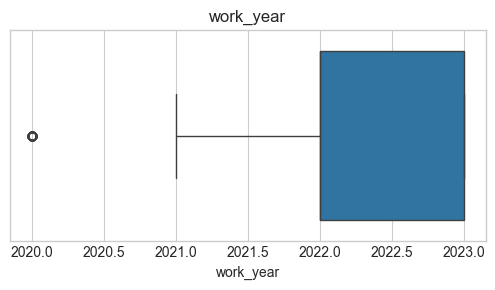

In [128]:
def plot_outliers(df, columns=None, columns_per_row=5, figsize_per_plot=(5, 3)):
    """
    Visualize potential outliers using boxplots.
    """
    if columns is None:
        columns = numerical_features

    columns = [col for col in columns if col in df.columns]

    if not columns:
        print("No numerical features available.")
        return

    rows = (len(columns) + columns_per_row - 1) // columns_per_row

    fig, axes = plt.subplots(
        rows,
        columns_per_row,
        figsize=(
            figsize_per_plot[0] * columns_per_row,
            figsize_per_plot[1] * rows
        ),
        squeeze=False
    )

    for ax, column in zip(axes.flat, columns):
        sns.boxplot(x=df[column], ax=ax)
        ax.set_title(column)

    for ax in axes.flat[len(columns):]:
        ax.set_visible(False)

    plt.tight_layout()
    save_figure(filename="data_preparation-plot_outliers", fig=fig)
    plt.show()


plot_outliers(df_clean)

**Since the target variable is crucial for regression, let's inspect the outliers in the target column 'salary' before deciding to remove them.**

In [129]:
def handle_outliers_iqr(df, columns=None, multiplier=1.5):
    """
    Remove rows containing IQR-based outliers in selected numerical columns.
    Note: This removes entire rows and can remove legitimate values.
    """
    df = df.copy()

    if columns is None:
        columns = df.select_dtypes(include="number").columns.tolist()

    for column in columns:
        q1 = df[column].quantile(0.25)
        q3 = df[column].quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - multiplier * iqr
        upper_bound = q3 + multiplier * iqr

        df = df[
            df[column].between(lower_bound, upper_bound) |
            df[column].isna()
        ]

    return df

df_clean_outliers = handle_outliers_iqr(df_clean)
print("Outlier Summary After Handling Outliers:")
display(outlier_summary(df_clean_outliers))

print("Shape after handling outliers:", df_clean_outliers.shape)

# Since the target variable is crucial for regression, let's inspect the outliers in the target column 'salary' before deciding to remove them.

Outlier Summary After Handling Outliers:


,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
0,work_year,2020.5,2024.5,0,0.0


Shape after handling outliers: (2305, 7)


### Save Clean Data

In [130]:
save_data(data=df_clean, filename="data_preprocessing-clean_data")

Data saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\data\processed\data_preprocessing-clean_data.csv


WindowsPath('c:/Users/samuel.ablorh/Repository/Data-Workspace/projects/machine-learning/employee-salary-prediction/data/processed/data_preprocessing-clean_data.csv')

## Exploratory Data Analysis

### Target Variable Distribution

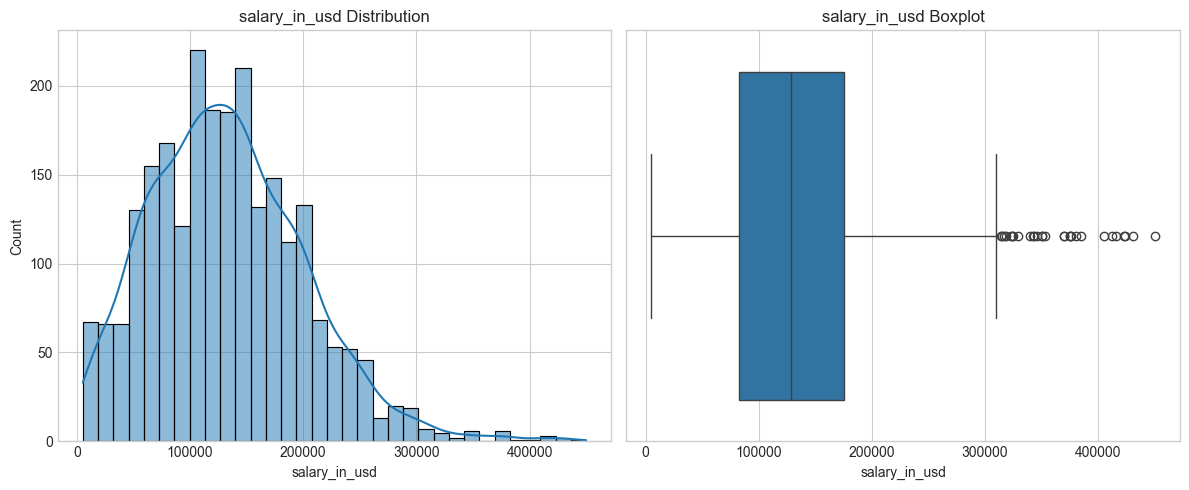

Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\figures\eda-plot_target_distribution.png


In [131]:
def plot_target_distribution(df, target=TARGET_COLUMN, figsize=(12, 5)):
    """
    Plot the target variable's distribution and boxplot.
    """
    if target not in df.columns:
        raise ValueError(f"Target column '{target}' not found.")

    fig, axes = plt.subplots(1, 2, figsize=figsize)

    sns.histplot(df[target].dropna(), kde=True, ax=axes[0])
    axes[0].set_title(f"{target} Distribution")
    axes[0].set_xlabel(target)

    sns.boxplot(x=df[target], ax=axes[1])
    axes[1].set_title(f"{target} Boxplot")
    axes[1].set_xlabel(target)

    plt.tight_layout()
    plt.show()

    save_figure(filename="eda-plot_target_distribution", fig=fig)

plot_target_distribution(df_clean, target=TARGET_COLUMN)

In [132]:
def summarize_target_distribution(df, target=TARGET_COLUMN):
    """
    Display descriptive statistics and skewness for the target.
    """
    if target not in df.columns:
        raise ValueError(f"Target column '{target}' not found.")

    df_describe = df[target].describe().to_frame()

    print(f"Target: {target}")
    print(f"Skewness: {df[target].skew():.3f}")
    print("\nDescriptive Statistics:")
    display(df_describe)
    save_table(table=df_describe, filename="eda-target_distribution_summary", index=True)


summarize_target_distribution(df_clean, target=TARGET_COLUMN)

Target: salary_in_usd
Skewness: 0.637

Descriptive Statistics:


,salary_in_usd
count,2404.000000
mean,132840.516223
std,68416.863930
min,5132.000000
25%,82521.000000
50%,128625.000000
75%,175025.000000
max,450000.000000


Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\tables\eda-target_distribution_summary.csv


### Numerical Feature Distributions

Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\figures\eda-plot_numerical_distributions.png


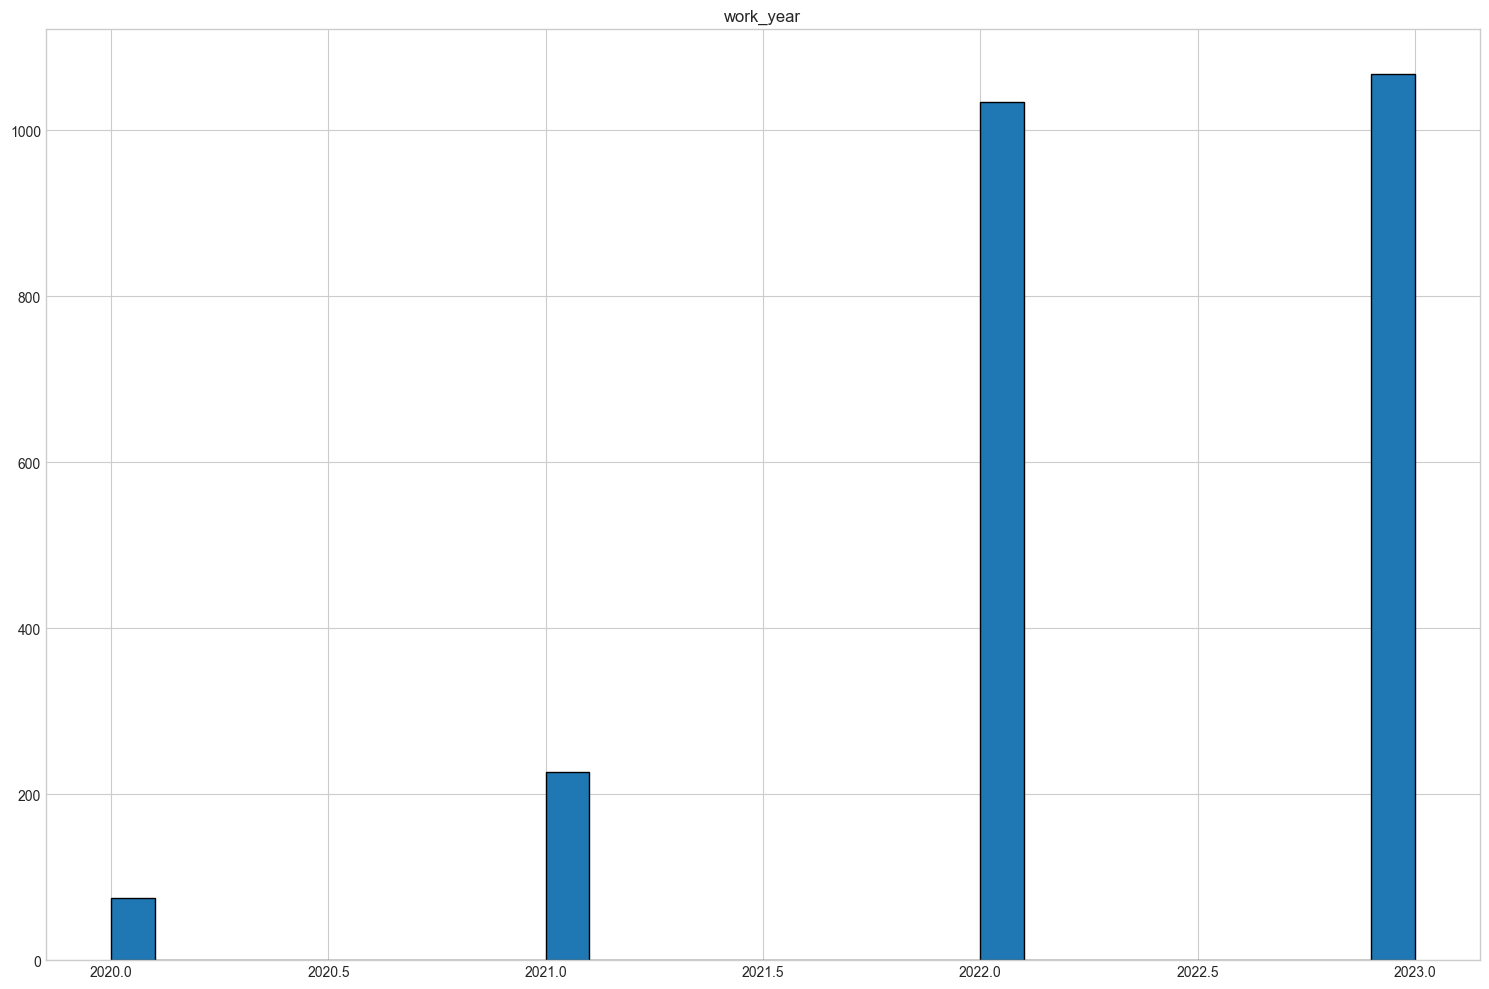

In [133]:
def plot_numerical_distributions(df, exclude=None, columns_per_row=3, figsize=(15, 10)):
    """
    Plot histograms and KDE curves for numerical features.
    """
    numeric_df = df[numerical_features]
    exclude = exclude or []

    numeric_df = numeric_df.drop(
        columns=exclude, errors="ignore"
    )

    if numeric_df.empty:
        print("No numerical features available.")
        return

    numeric_df.hist(
        bins=30,
        figsize=figsize,
        layout=None,
        edgecolor="black"
    )

    plt.tight_layout()
    save_figure(filename="eda-plot_numerical_distributions")
    
    plt.show()



plot_numerical_distributions(df_clean, exclude=[TARGET_COLUMN, *EXCLUDE_COLUMNS])

In [134]:
def summarize_numerical_distributions(df, exclude=None):
    """
    Display descriptive statistics and skewness for numerical features.
    """
    numeric_df = df[numerical_features]
    exclude = exclude or []

    numeric_df = numeric_df.drop(
        columns=exclude, errors="ignore"
    )

    summary = numeric_df.describe().T
    summary["skewness"] = numeric_df.skew()
    summary["missing_count"] = numeric_df.isna().sum()

    save_table(table=summary, filename="eda-numerical_distribution_summary", index=True)

    print("Numerical Features Summary: \n")
    display(summary)


summarize_numerical_distributions(df_clean, exclude=[TARGET_COLUMN, *EXCLUDE_COLUMNS])

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\tables\eda-numerical_distribution_summary.csv
Numerical Features Summary: 



,count,mean,std,min,25%,50%,75%,max,skewness,missing_count
work_year,2404.0,2022.287438,0.762298,2020.0,2022.0,2022.0,2023.0,2023.0,-0.959227,0


### Categorical Feature Distributions

Categorical Distributions: 

Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\figures\eda-plot_categorical_distributions.png


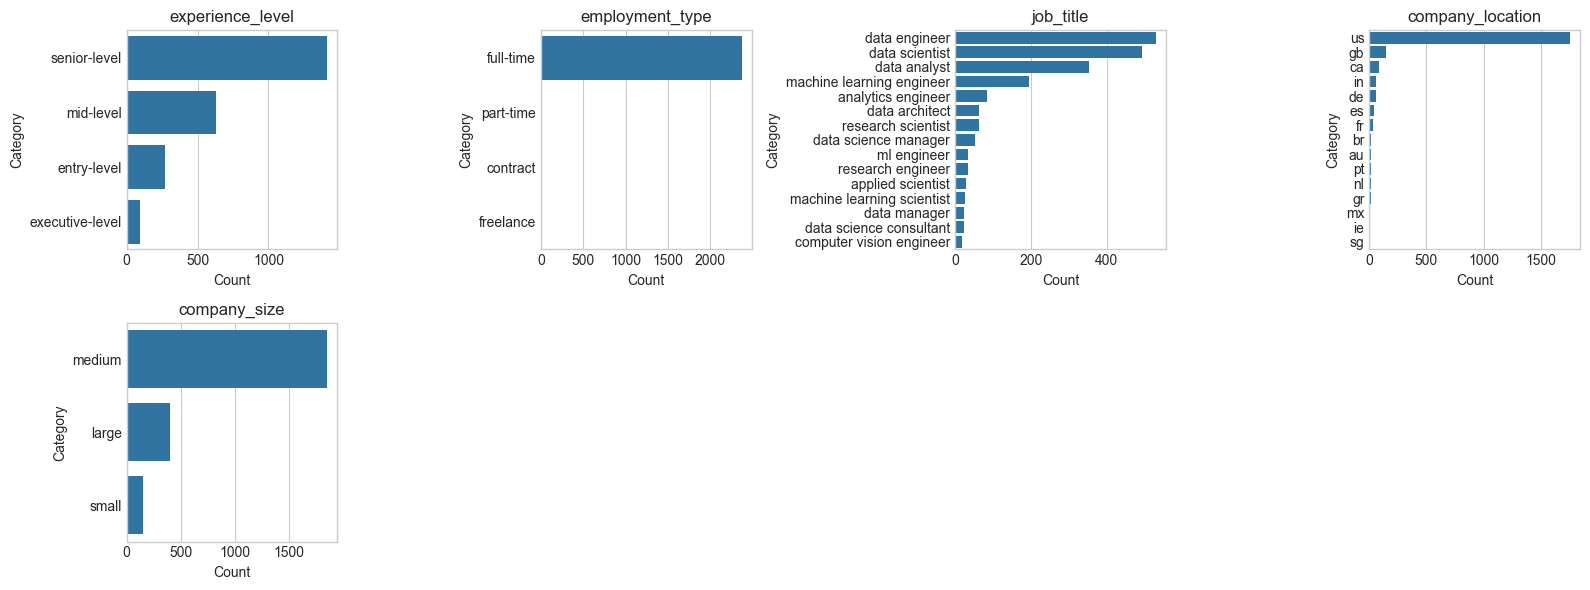

In [135]:
def plot_categorical_distributions(
    df,
    columns=None,
    max_categories=15,
    columns_per_row=4,
    figsize_per_plot=(4, 3)
):
    """
    Plot categorical feature distributions using subplots.
    """
    if columns is None:
        columns = categorical_features

    if not columns:
        print("No categorical features available.")
        return

    n_features = len(columns)
    rows = (n_features + columns_per_row - 1) // columns_per_row

    fig, axes = plt.subplots(
        rows,
        columns_per_row,
        figsize=(
            figsize_per_plot[0] * columns_per_row,
            figsize_per_plot[1] * rows
        ),
        squeeze=False
    )

    for ax, column in zip(axes.flat, columns):
        counts = df[column].value_counts(dropna=False).head(max_categories)

        sns.barplot(
            x=counts.values,
            y=counts.index.astype(str),
            ax=ax
        )
        ax.set_title(column)
        ax.set_xlabel("Count")
        ax.set_ylabel("Category")

    for ax in axes.flat[n_features:]:
        ax.set_visible(False)

    plt.tight_layout()
    save_figure(filename="eda-plot_categorical_distributions", fig=fig)
    plt.show()

print("Categorical Distributions: \n")
plot_categorical_distributions(df_clean)

In [136]:
def summarize_categorical_distributions(df, columns=None):
    """
    Return one table of category counts and percentages.
    """
    if columns is None:
        columns = categorical_features

    summary = []

    for column in columns:
        counts = df[column].value_counts(dropna=False)

        for category, count in counts.items():
            summary.append({
                "feature": column,
                "category": category,
                "count": count,
                "percentage": round(count / len(df) * 100, 2)
            })

    df_summary=pd.DataFrame(summary)

    save_table(table=df_summary, filename="eda-categorical_distribution_summary")

    display(df_summary)


print("Categorical Distributions Summary: \n")
summarize_categorical_distributions(df_clean)

Categorical Distributions Summary: 

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\tables\eda-categorical_distribution_summary.csv


,feature,category,count,percentage
0,experience_level,senior-level,1415,58.86
1,experience_level,mid-level,627,26.08
2,experience_level,entry-level,267,11.11
3,experience_level,executive-level,95,3.95
4,employment_type,full-time,2367,98.46
...,...,...,...,...
171,company_location,md,1,0.04
172,company_location,mt,1,0.04
173,company_size,medium,1853,77.08
174,company_size,large,404,16.81


### Feature–Target Relationships

Feature-Target Relationships: 

Numerical Features vs Target: 
['work_year'] 

Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\figures\eda-plot_numerical_features_vs_target.png


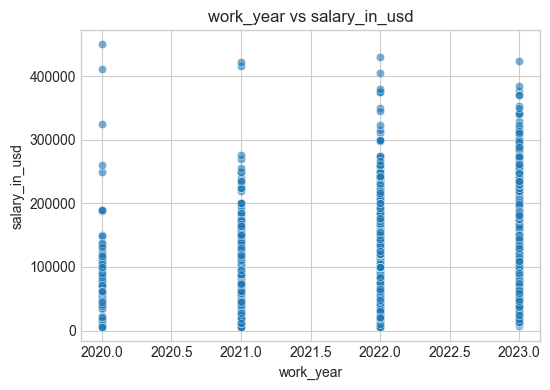

Categorical Features vs Target: 
['experience_level', 'employment_type', 'job_title', 'company_location', 'company_size'] 

Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\figures\eda-plot_categorical_features_vs_target.png


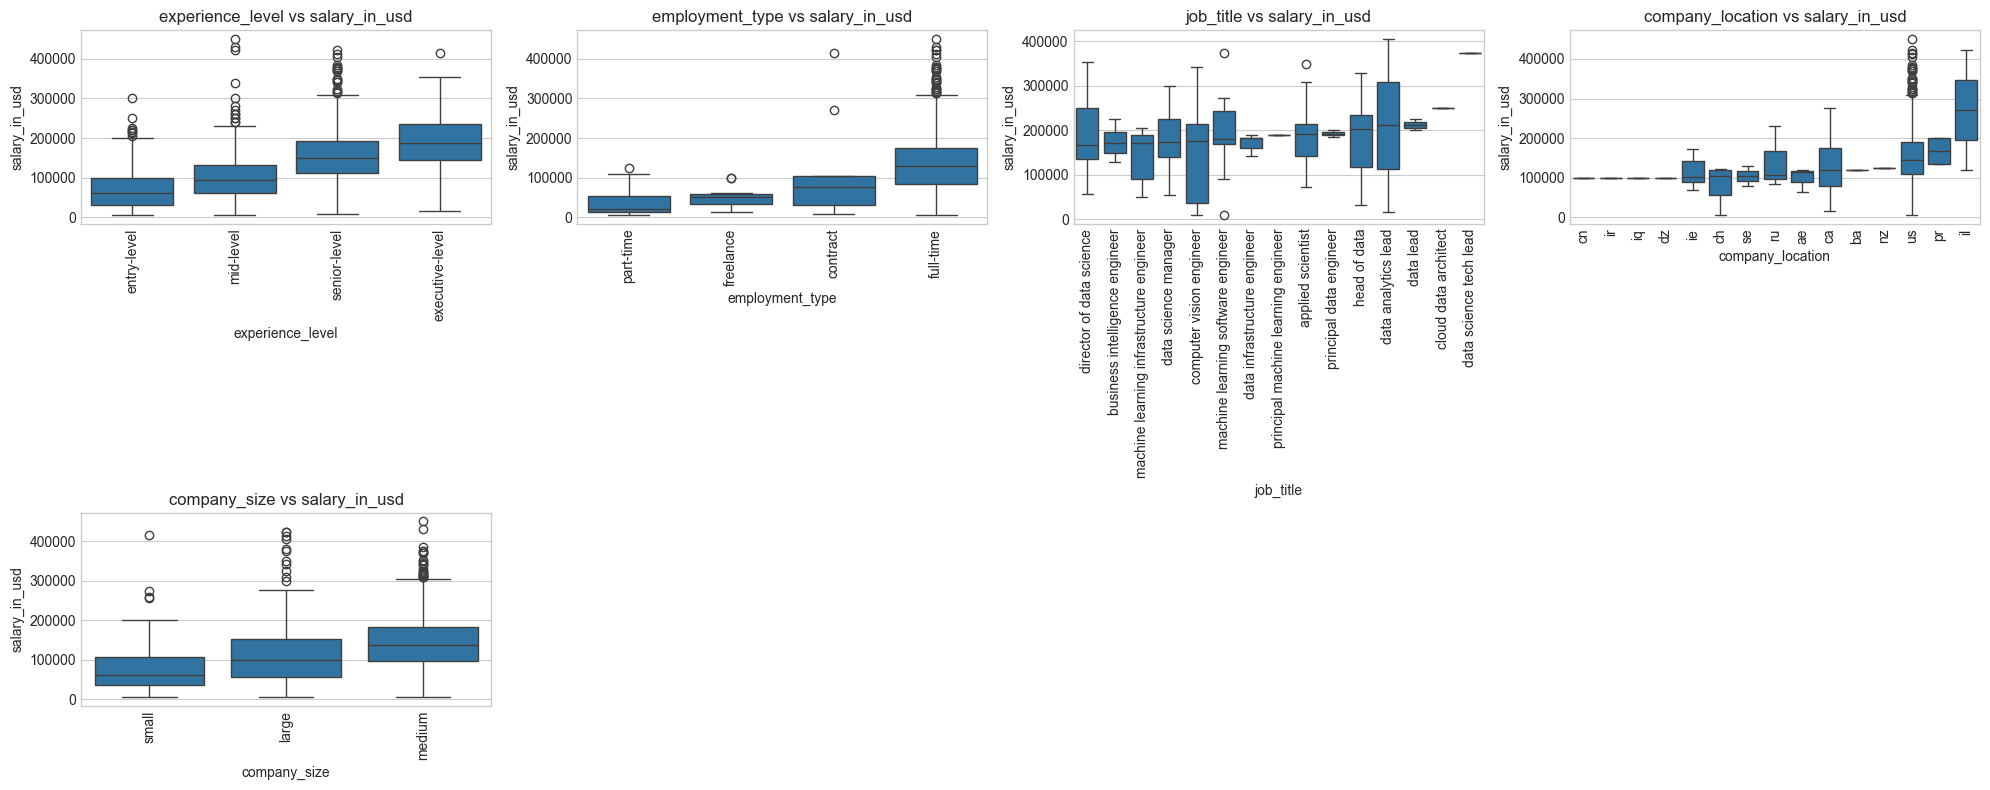

In [137]:
def plot_feature_target_relationships(
    df,
    target=TARGET_COLUMN,
    numerical_columns=None,
    categorical_columns=None,
    columns_per_row=4,
    figsize_per_plot=(5, 4),
    max_categories=15
):
    """
    Plot numerical and categorical feature relationships with the target.
    """
    if numerical_columns is None:
        numerical_columns = numerical_features

    if categorical_columns is None:
        categorical_columns = categorical_features

    numerical_columns = [
        col for col in numerical_columns
        if col != target and col in df.columns
    ]
    categorical_columns = [
        col for col in categorical_columns
        if col != target and col in df.columns
    ]

    print(f"Numerical Features vs Target: \n{numerical_columns} \n")

    # Numerical features vs target
    if numerical_columns:
        rows = (len(numerical_columns) + columns_per_row - 1) // columns_per_row

        fig, axes = plt.subplots(
            rows, columns_per_row,
            figsize=(
                figsize_per_plot[0] * columns_per_row,
                figsize_per_plot[1] * rows
            ),
            squeeze=False
        )

        for ax, column in zip(axes.flat, numerical_columns):
            sns.scatterplot(data=df, x=column, y=target, alpha=0.6, ax=ax)
            ax.set_title(f"{column} vs {target}")

        for ax in axes.flat[len(numerical_columns):]:
            ax.set_visible(False)

        plt.tight_layout()
        save_figure(filename="eda-plot_numerical_features_vs_target", fig=fig)
        plt.show()

    print(f"Categorical Features vs Target: \n{categorical_columns} \n")

    # Categorical features vs target
    if categorical_columns:
        rows = (len(categorical_columns) + columns_per_row - 1) // columns_per_row

        fig, axes = plt.subplots(
            rows, columns_per_row,
            figsize=(
                figsize_per_plot[0] * columns_per_row,
                figsize_per_plot[1] * rows
            ),
            squeeze=False
        )

        for ax, column in zip(axes.flat, categorical_columns):
            order = (
                df.groupby(column, observed=True)[target]
                .median()
                .sort_values()
                .tail(max_categories)
                .index
            )

            sns.boxplot(
                data=df[df[column].isin(order)],
                x=column,
                y=target,
                order=order,
                ax=ax
            )
            ax.set_title(f"{column} vs {target}")
            ax.tick_params(axis="x", rotation=90)

        for ax in axes.flat[len(categorical_columns):]:
            ax.set_visible(False)

        plt.tight_layout()
        save_figure(filename="eda-plot_categorical_features_vs_target", fig=fig)
        plt.show()

print("Feature-Target Relationships: \n")
plot_feature_target_relationships(df_clean)

### Correlation Analysis

Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\figures\eda-correlation_heatmap.png


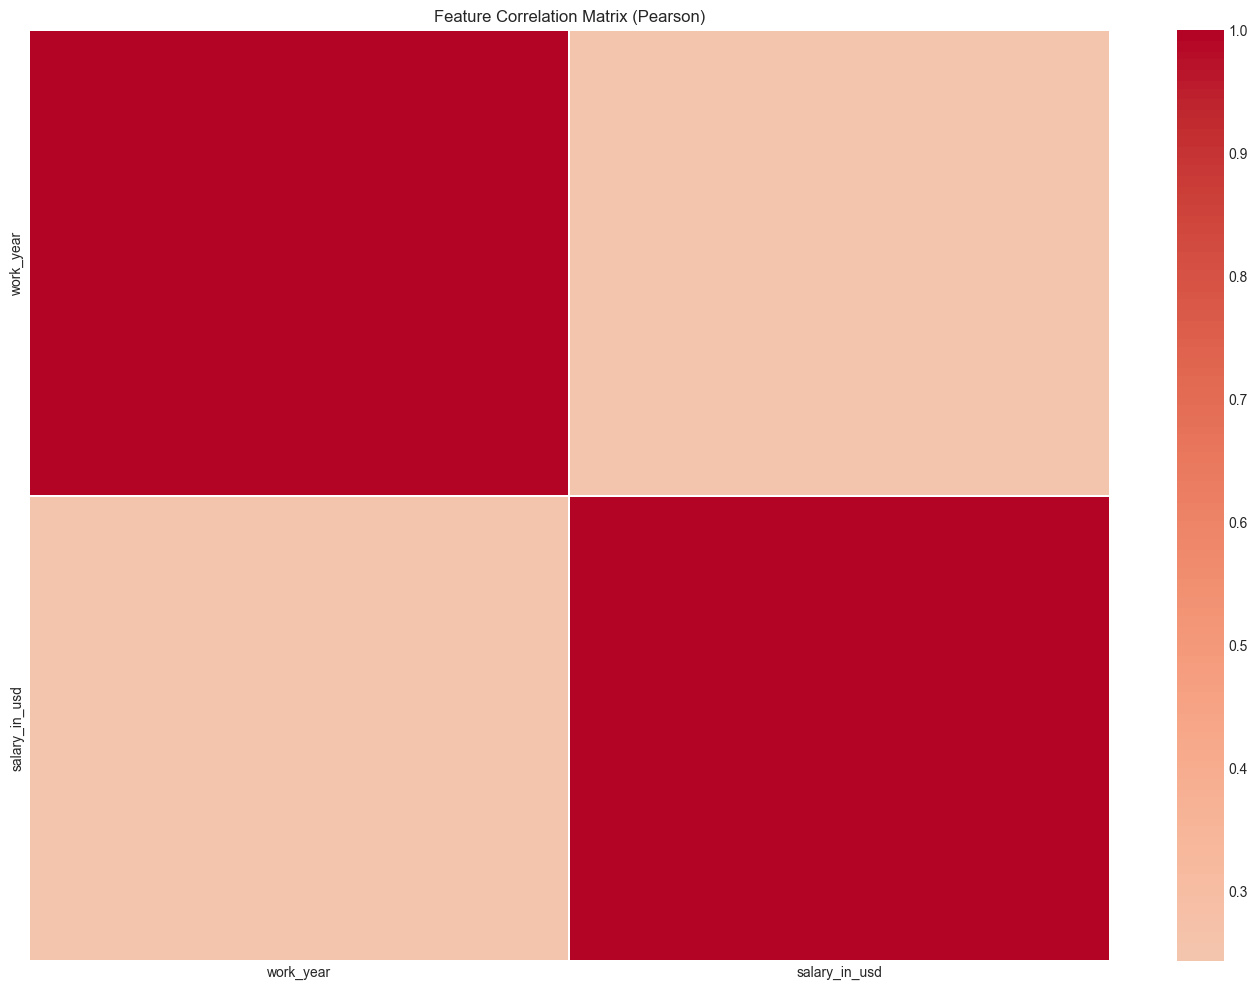

Top 20 features correlated with salary_in_usd:
Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\tables\eda-target_correlation_table.csv


,correlation_with_target
work_year,0.24371


In [138]:
def correlation_analysis(
    df,
    target=TARGET_COLUMN,
    method="pearson",
    top_n=20,
    figsize=(14, 10)
):
    """
    Display a correlation heatmap and features most correlated with the target.
    """
    numeric_df = df.select_dtypes(include="number").drop(
        columns=["Id"], errors="ignore"
    )

    correlations = numeric_df.corr(method=method)

    # Correlation heatmap
    fig = plt.figure(figsize=figsize)
    sns.heatmap(
        correlations,
        cmap="coolwarm",
        center=0,
        linewidths=0.3
    )
    plt.title(f"Feature Correlation Matrix ({method.title()})")
    plt.tight_layout()
    save_figure(filename="eda-correlation_heatmap", fig=fig)
    plt.show()

    # Features most correlated with the target
    if target in correlations.columns:
        target_corr = (
            correlations[target]
            .drop(target)
            .dropna()
            .sort_values(key=abs, ascending=False)
            .head(top_n)
            .to_frame("correlation_with_target")
        )

        print(f"Top {top_n} features correlated with {target}:")

        save_table(table=target_corr, filename="eda-target_correlation_table", index=True)
        display(target_corr)


correlation_analysis(df_clean)

### Outlier Investigation

In [139]:
print("Outlier Summary:")  
save_table(table=outlier_summary(df_clean), filename="eda-outlier_summary")
display(outlier_summary(df_clean))

Outlier Summary:
Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\tables\eda-outlier_summary.csv


,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
0,work_year,2020.5,2024.5,75,3.12


Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\figures\data_preparation-plot_outliers.png


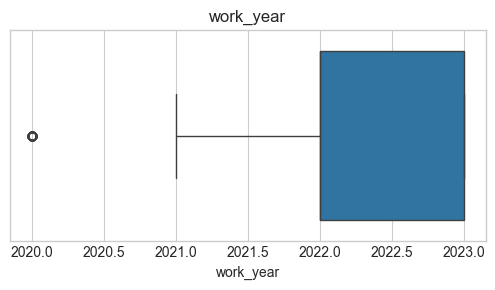

In [140]:
plot_outliers(df_clean)

## Data Spliting

In [138]:
df_working = df_clean.copy()

In [139]:
# Separate features and target.
X = df_working.drop(columns=[TARGET_COLUMN, *EXCLUDE_COLUMNS], errors="ignore")
y = df_working[TARGET_COLUMN]

# Split into training and test sets.
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=TEST_SIZE,random_state=RANDOM_STATE)

save_data(data=X_train, filename="data_preprocessing-x_train_raw")
save_data(data=X_test, filename="data_preprocessing-x_test_raw")
save_data(data=y_train, filename="data_preprocessing-y_train_raw")
save_data(data=y_test, filename="data_preprocessing-y_test_raw")

Data saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\data\processed\data_preprocessing-x_train_raw.csv
Data saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\data\processed\data_preprocessing-x_test_raw.csv
Data saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\data\processed\data_preprocessing-y_train_raw.csv
Data saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\data\processed\data_preprocessing-y_test_raw.csv


WindowsPath('c:/Users/samuel.ablorh/Repository/Data-Workspace/projects/machine-learning/employee-salary-prediction/data/processed/data_preprocessing-y_test_raw.csv')

In [178]:
def sample_training_data(X_train, y_train, sample_size=50_000, random_state=RANDOM_STATE):
    """
    Randomly samples training data when it exceeds the specified sample size,
    keeping the features and target values aligned.

    Returns the sampled or original training features and target values.
    """
    try:
        if len(X_train) != len(y_train):
            raise ValueError("X_train and y_train must contain the same number of rows.")

        if not X_train.index.equals(y_train.index):
            raise ValueError("X_train and y_train must have matching indexes in the same order.")

        if not isinstance(sample_size, int) or isinstance(sample_size, bool) or sample_size <= 0:
            raise ValueError("sample_size must be a positive integer.")

        if len(X_train) > sample_size:
            X_train_sampled = X_train.sample(
                n=sample_size,
                random_state=random_state
            )
            y_train_sampled = y_train.loc[X_train_sampled.index]

            print(f"Training data sampled: {sample_size:,} of {len(X_train):,} rows.")

        else:
            X_train_sampled = X_train.copy()
            y_train_sampled = y_train.copy()

            print(f"Sampling skipped: using all {len(X_train):,} training rows.")

        return X_train_sampled, y_train_sampled

    except (ValueError, TypeError, AttributeError) as error:
        raise type(error)(f"Training data sampling failed: {error}") from error


X_train_sampled, y_train_sampled = sample_training_data(
    X_train=X_train,
    y_train=y_train
)

Sampling skipped: using all 50,000 training rows.


In [141]:
X_train = X_train_sampled
y_train = y_train_sampled

## Feature Engineering

### Feature Creation

In [142]:
# Create a feature engineering transformer to add new features
class FeatureCreator(BaseEstimator, TransformerMixin):
    """
    Create additional features for the Employee Salary Prediction dataset.

    Available features:
        experience_level:
            Groups years of experience into career levels.

        skills_per_certification:
            Calculates the number of skills relative to certifications.
    """

    def __init__(self, features_to_create=None):
        self.features_to_create = features_to_create

    def fit(self, X, y=None):
        """Learn nothing; features use fixed row-wise calculations."""
        self.is_fitted_ = True
        return self

    def transform(self, X):
        """Create selected engineered features."""
        X = X.copy()

        features_to_create = self.features_to_create or []

        if "experience_level" in features_to_create:
            X["experience_level"] = pd.cut(
                X["experience_years"],
                bins=[-float("inf"), 2, 5, 10, float("inf")],
                labels=["Entry-level", "Mid-level", "Senior", "Expert"]
            )

        if "skills_per_certification" in features_to_create:
            X["skills_per_certification"] = (
                X["skills_count"] / (X["certifications"] + 1)
            )

        return X

### Feature Transformation

In [143]:
# No log transformation for this project 

### Baseline Feature Engineering Pipeline

In [144]:
baseline_feature_engineering_pipeline = Pipeline([
    ("feature_creation", FeatureCreator(features_to_create=FEATURES_TO_CREATE))
])

## Data Preprocessing

### Create Preprocessor

In [145]:
def create_preprocessor():
    """
    Prepare numerical and categorical features for machine learning.

    Numerical features:
        - Fill missing values with the median.
        - Standardize values to a common scale.

    Categorical features:
        - Fill missing values with the most frequent category.
        - Convert categories into numerical columns using one-hot encoding.
    """


    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy=NUMERICAL_IMPUTATION)),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("normalize_missing", FunctionTransformer(
            normalize_missing_values,
            validate=False
        )),
        ("imputer", SimpleImputer(strategy=CATEGORICAL_IMPUTATION)),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer(
        transformers=[
            ("numerical", numerical_pipeline, make_column_selector(dtype_include="number")),
            ("categorical", categorical_pipeline, make_column_selector(
                dtype_include=["object", "category", "bool"]
            ))
        ],
        remainder="drop"
    )

### Preprocessor Pipeline

In [146]:
preprocessor_pipeline = create_preprocessor()

## Baseline Model Developement

### Create Baseline Model Pipeline

In [147]:
baseline_model_pipeline = Pipeline([
    ("feature_engineering", baseline_feature_engineering_pipeline),
    ("preprocessor", preprocessor_pipeline),
    ("model", BASELINE_MODEL)
])

### Train Baseline Model

In [148]:
baseline_model_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_creation', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,features_to_create,"['experience_level', 'skills_per_certification']"
Name,Type,Value
is_fitted_,bool,True


### Evaluate Baseline Model

In [149]:
y_pred = baseline_model_pipeline.predict(X_test)

baseline_metrics = {
    key: config["calculate"](y_test, y_pred)
    for key, config in REGRESSION_METRICS.items()
    if "calculate" in config
}

baseline_results = pd.DataFrame([baseline_metrics])

save_table(table=baseline_results, filename="baseline_model-baseline_results")
print("BASELINE TEST-SET RESULTS")
display(baseline_results)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\tables\baseline_model-baseline_results.csv
BASELINE TEST-SET RESULTS


,RMSE,MAE,R2
0,33142.196552,26218.492776,0.209703


### Cross-Validate Baseline Model

In [150]:
# Evaluate the complete pipeline using training data only.
cv_scores = cross_val_score(
    baseline_model_pipeline,
    X_train,
    y_train,
    cv=CROSS_VALIDATION_FOLDS,
    scoring=SCORING_METRIC
)

# Convert negative RMSE scores to positive values.
cv_rmse_scores = -cv_scores

# ============================================================
# DISPLAY BASELINE CROSS-VALIDATION RESULTS
# ============================================================

cv_mean_label = REGRESSION_METRICS["CV_MEAN_RMSE"]["label"]
cv_std_label = REGRESSION_METRICS["CV_RMSE_STD"]["label"]

print(f"{REGRESSION_METRICS['RMSE']['label']} per fold:")
print(cv_rmse_scores)

print(f"{cv_mean_label}: {cv_rmse_scores.mean():,.4f}")
print(f"{cv_std_label}: {cv_rmse_scores.std():,.4f}")

Root Mean Squared Error per fold:
[33310.89129637 33301.71004324 32830.19260429 32858.29239462
 33266.31421626]
Mean Cross-Validation RMSE: 33,113.4801
Cross-Validation RMSE Standard Deviation: 220.5142


### Baseline Result Summary

In [151]:
# Baseline Cross-Validation Summary
cv_mean_column = REGRESSION_METRICS[
    "CV_MEAN_RMSE"
]["result_columns"]["baseline"]

cv_std_column = REGRESSION_METRICS[
    "CV_RMSE_STD"
]["result_columns"]["baseline"]

baseline_results[cv_mean_column] = cv_rmse_scores.mean()
baseline_results[cv_std_column] = cv_rmse_scores.std()

save_table(table=baseline_results, filename="baseline_model-baseline_results_summary")
print("BASELINE RESULTS INCLUDING CROSS-VALIDATION")
display(baseline_results)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\tables\baseline_model-baseline_results_summary.csv
BASELINE RESULTS INCLUDING CROSS-VALIDATION


,RMSE,MAE,R2,CV_Mean_RMSE,CV_RMSE_Std
0,33142.196552,26218.492776,0.209703,33113.480111,220.514185


## Model Improvement

### Multicollinearity Analysis

In [152]:
def analyze_multicollinearity(
    X,
    threshold=CORRELATION_THRESHOLD,
    exclude=None,
):
    """
    Identify numerical feature pairs with high absolute correlation.

    Creates engineered features on a temporary copy and returns
    pairs whose absolute correlation meets the threshold.
    """
    # Create a temporary copy with engineered features.
    X_analysis = FeatureCreator(features_to_create=FEATURES_TO_CREATE).fit_transform(X)

    # Identify numerical features.
    numerical_features, _ = get_feature_types(
        X_analysis,
        exclude=exclude or []
    )

    # Calculate the absolute correlation matrix.
    correlation_matrix = (
        X_analysis[numerical_features]
        .corr()
        .abs()
    )

    # Extract unique feature pairs.
    upper_triangle = correlation_matrix.where(
        np.triu(
            np.ones(correlation_matrix.shape),
            k=1
        ).astype(bool)
    )

    high_correlations = (
        upper_triangle
        .stack()
        .reset_index()
    )

    high_correlations.columns = [
        "Feature 1",
        "Feature 2",
        "Absolute Correlation"
    ]

    # Filter and rank highly correlated pairs.
    high_correlations = (
        high_correlations[
            high_correlations["Absolute Correlation"] >= threshold
        ]
        .sort_values(
            "Absolute Correlation",
            ascending=False
        )
        .reset_index(drop=True)
    )

    return high_correlations


high_correlations = analyze_multicollinearity(
    X_train,
    threshold=CORRELATION_THRESHOLD,
    exclude=[*EXCLUDE_COLUMNS]
)

print("High Correlation Features:")
display(high_correlations)

High Correlation Features:


,Feature 1,Feature 2,Absolute Correlation


### VIF - Multicolinearity

In [153]:
def calculate_vif(df, exclude=None, threshold=VIF_THRESHOLD):
    """
    Calculate VIF after removing constant and linearly dependent features.
    Returns the VIF results and the columns excluded from the calculation.
    """

    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    numerical_features, _ = get_feature_types(
        df,
        exclude=exclude or []
    )

    X = df[numerical_features].dropna(axis=1, how="all")

    if X.shape[1] < 2:
        raise ValueError("At least two usable numerical features are required.")

    X = pd.DataFrame(
        SimpleImputer(strategy="median").fit_transform(X),
        columns=X.columns,
        index=X.index
    )

    # Remove constant columns.
    X = X.loc[:, X.nunique() > 1]

    # Keep only linearly independent columns.
    independent = []
    excluded = []

    for column in X.columns:
        candidate = X[independent + [column]].to_numpy()

        if np.linalg.matrix_rank(candidate) > len(independent):
            independent.append(column)
        else:
            excluded.append(column)

    X = X[independent]

    if X.shape[1] < 2:
        raise ValueError("Fewer than two independent numerical features remain.")

    results = pd.DataFrame({
        "Feature": X.columns,
        "VIF": [
            variance_inflation_factor(X.to_numpy(), i)
            for i in range(X.shape[1])
        ]
    }).sort_values("VIF", ascending=False).reset_index(drop=True)

    excluded_results = pd.DataFrame({
        "Excluded_Feature": excluded
    })

    features_to_remove = results.loc[
        results["VIF"] > threshold, "Feature"
    ].tolist()

    return results, excluded_results, features_to_remove


vif_results, vif_excluded, vif_features_to_remove = calculate_vif(
    X_train,
    exclude=[*EXCLUDE_COLUMNS],
    threshold=VIF_THRESHOLD
)

save_table(table=vif_results, filename="model_improvement-vif_results")
print("\nVIF Results:")
display(vif_results)

save_table(table=vif_excluded, filename="model_improvement-vif_excluded")
print("\nFeatures excluded from VIF calculation due to exact linear dependence:")
display(vif_excluded)

print("\nFeatures to review for removal based on VIF:")
print(vif_features_to_remove)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\tables\model_improvement-vif_results.csv

VIF Results:


,Feature,VIF
0,certifications,1.000012
1,experience_years,1.000008
2,skills_count,1.000005


Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\tables\model_improvement-vif_excluded.csv

Features excluded from VIF calculation due to exact linear dependence:


,Excluded_Feature



Features to review for removal based on VIF:
[]


### Cramers-V - Categorical Multicolinearity

In [154]:
def calculate_cramers_v(df, exclude=None, threshold=CORRELATION_THRESHOLD):
    """
    Calculate Cramér's V for pairs of categorical features.

    Returns:
        results: Cramér's V results.
        excluded_results: Pairs excluded from calculation.
        multicollinear_features: Unique features in highly associated pairs.
    """

    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    if not 0 <= threshold <= 1:
        raise ValueError("threshold must be between 0 and 1.")

    _, categorical_features = get_feature_types(
        df,
        exclude=exclude or []
    )

    X = df[categorical_features].copy()

    if len(categorical_features) < 2:
        raise ValueError("At least two categorical features are required.")

    results = []
    excluded = []

    for i, feature_1 in enumerate(categorical_features):
        for feature_2 in categorical_features[i + 1:]:

            pair = X[[feature_1, feature_2]].dropna()

            if pair[feature_1].nunique() < 2 or pair[feature_2].nunique() < 2:
                excluded.append({
                    "Feature_1": feature_1,
                    "Feature_2": feature_2,
                    "Reason": "Constant feature or insufficient variation"
                })
                continue

            contingency_table = pd.crosstab(
                pair[feature_1],
                pair[feature_2]
            )

            chi2 = stats.chi2_contingency(
                contingency_table,
                correction=False
            )[0]

            n = contingency_table.to_numpy().sum()
            rows, cols = contingency_table.shape

            cramers_v = np.sqrt(
                chi2 / (n * min(rows - 1, cols - 1))
            )

            results.append({
                "Feature_1": feature_1,
                "Feature_2": feature_2,
                "Cramers_V": cramers_v
            })

    results = pd.DataFrame(results)

    if not results.empty:
        results = results.sort_values(
            "Cramers_V",
            ascending=False
        ).reset_index(drop=True)

        high_association = results[
            results["Cramers_V"] >= threshold
        ]

        multicollinear_features = sorted(set(
            high_association["Feature_1"].tolist()
            + high_association["Feature_2"].tolist()
        ))
    else:
        multicollinear_features = []

    excluded_results = pd.DataFrame(excluded)

    return results, excluded_results, multicollinear_features

In [155]:
cramers_v_results, cramers_v_excluded, categorical_features_to_review = (
    calculate_cramers_v(
        X_train,
        exclude=[*EXCLUDE_COLUMNS],
        threshold=CORRELATION_THRESHOLD
    )
)

save_table(
    table=cramers_v_results,
    filename="model_improvement-cramers_v_results"
)

print("\nCramér's V Results:")
display(cramers_v_results)

save_table(
    table=cramers_v_excluded,
    filename="model_improvement-cramers_v_excluded"
)

print("\nCramér's V Excluded:")
display(cramers_v_excluded)


print("Categorical features to review:")
print(categorical_features_to_review)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\tables\model_improvement-cramers_v_results.csv

Cramér's V Results:


,Feature_1,Feature_2,Cramers_V
0,job_title,remote_work,0.017928
1,job_title,industry,0.016944
2,job_title,education_level,0.016153
3,job_title,company_size,0.015713
4,job_title,location,0.015384
5,industry,remote_work,0.014891
6,industry,company_size,0.014138
7,company_size,location,0.013467
8,education_level,location,0.013323
9,industry,location,0.012162


Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\tables\model_improvement-cramers_v_excluded.csv

Cramér's V Excluded:


""


Categorical features to review:
[]


### Multicolinear Features

In [156]:
MULTICOLLINEAR_FEATURES = []

## Update Feature Engineering Pipeline

### Feature Dropper

In [157]:
class FeatureDropper(BaseEstimator, TransformerMixin):
    """Remove specified features after feature engineering."""

    def __init__(self, features_to_drop=None):
        self.features_to_drop = features_to_drop

    def fit(self, X, y=None):
        """Learn nothing; features use fixed row-wise calculations."""
        self.is_fitted_ = True
        return self

    def transform(self, X):
        X = X.copy()
        features = self.features_to_drop or []
        return X.drop(columns=features, errors="ignore")

### Update Feature Engineering Pipeline

In [158]:
feature_engineering_pipeline = Pipeline([
    ("feature_creation", FeatureCreator(features_to_create=FEATURES_TO_CREATE)),
    ("feature_dropper", FeatureDropper(features_to_drop=MULTICOLLINEAR_FEATURES)),
])

## Regression Models Developement

### Regression Model Pipeline

In [159]:
regression_models = {
    name: clone(config["estimator"])
    for name, config in REGRESSION_MODEL_CONFIG.items()
}

regression_pipelines = {}

for name, model in regression_models.items():
    regression_pipelines[name] = Pipeline([
        ("feature_engineering", clone(feature_engineering_pipeline)),
        ("preprocessor", clone(preprocessor_pipeline)),
        ("model", model)
    ])

### Train Regression Models

In [160]:
for name, pipeline in regression_pipelines.items():
    print(f"Training {name}...", flush=True)
    pipeline.fit(X_train, y_train)
    print(f"{name} trained successfully.", flush=True)

Training Linear Regression...
Linear Regression trained successfully.
Training Ridge...
Ridge trained successfully.
Training Lasso...
Lasso trained successfully.
Training Elastic Net...
Elastic Net trained successfully.
Training Random Forest...
Random Forest trained successfully.
Training Gradient Boosting...
Gradient Boosting trained successfully.
Training KNN...
KNN trained successfully.


### Evaluate Regression Models

In [161]:
# Evaluate Regression Models
evaluation_results = []

for name, pipeline in regression_pipelines.items():
    y_pred = pipeline.predict(X_test)

    result = {"Model": name}

    for key, config in REGRESSION_METRICS.items():
        if "calculate" in config:
            result[config["column"]] = config["calculate"](
                y_test, y_pred
            )

    evaluation_results.append(result)

rmse_column = REGRESSION_METRICS["RMSE"]["column"]

improved_model_results = (
    pd.DataFrame(evaluation_results)
    .sort_values(by=rmse_column)
    .reset_index(drop=True)
)

save_table(table=improved_model_results, filename="model_building-improved_models_results")
print("IMPROVED MODELS RESULTS")
display(improved_model_results)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\tables\model_building-improved_models_results.csv
IMPROVED MODELS RESULTS


,Model,RMSE,MAE,R2
0,Lasso,33142.106777,26218.420117,0.209707
1,Linear Regression,33142.196552,26218.492776,0.209703
2,Ridge,33142.199533,26218.495949,0.209703
3,Gradient Boosting,33171.420256,26247.203047,0.208309
4,Elastic Net,33541.447572,26550.967829,0.190547
5,Random Forest,33968.027924,26881.259753,0.169827
6,KNN,36226.822378,28724.921656,0.055747


### Cross-Validate Regression models

In [162]:
# Cross-Validate Improved Models
cv_results = []

cv_scoring = REGRESSION_METRICS[
    "CV_MEAN_RMSE"
]["scoring"]

cv_mean_column = REGRESSION_METRICS[
    "CV_MEAN_RMSE"
]["result_columns"]["initial_cv"]

cv_std_column = REGRESSION_METRICS[
    "CV_RMSE_STD"
]["result_columns"]["initial_cv"]

for name, pipeline in regression_pipelines.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=CROSS_VALIDATION_FOLDS,
        scoring=cv_scoring,
        n_jobs=-1
    )

    # Convert sklearn's negative RMSE scores to positive RMSE.
    rmse_scores = -scores["test_score"]

    cv_results.append({
        "Model": name,
        cv_mean_column: rmse_scores.mean(),
        cv_std_column: rmse_scores.std()
    })

improved_cv_results = (
    pd.DataFrame(cv_results)
    .sort_values(cv_mean_column)
    .reset_index(drop=True)
)

save_table(table=improved_model_results, filename="model_building-cross_validation_model_improved_results")
print("CROSS-VALIDATION RESULTS")
display(improved_cv_results)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\tables\model_building-cross_validation_model_improved_results.csv
CROSS-VALIDATION RESULTS


,Model,Mean CV RMSE,Std CV RMSE
0,Lasso,33113.397551,220.473811
1,Ridge,33113.478835,220.510321
2,Linear Regression,33113.480111,220.514185
3,Gradient Boosting,33147.773654,232.224064
4,Elastic Net,33497.902123,216.456859
5,Random Forest,34129.025510,231.176712
6,KNN,36284.959966,294.912658


### Hyperparameter Tuning

#### Model Params

In [163]:
param_grids = {
    name: config["param_grid"]
    for name, config in REGRESSION_MODEL_CONFIG.items()
}

#### Hyperparameter Tunning

In [164]:
def tune_regression_models(
    regression_pipelines,
    param_grids,
    X_train,
    y_train,
    cv=CROSS_VALIDATION_FOLDS,
    scoring=None
):
    """
    Tune multiple regression pipelines using GridSearchCV.
    Selects the best hyperparameters for each model through cross-validation,
    evaluates models using the specified scoring metric, saves and displays
    the tuning results sorted by mean cross-validation RMSE, and returns the
    best fitted models and the tuning results DataFrame.
    """

    if scoring is None:
        scoring = REGRESSION_METRICS["RMSE"]["scoring"]

    best_models = {}
    tuning_results = []

    tuned_cv_column = REGRESSION_METRICS[
        "CV_MEAN_RMSE"
    ]["result_columns"]["tuned_cv"]

    for name, pipeline in regression_pipelines.items():

        print(f"\nTuning model: {name}")

        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grids[name],
            cv=cv,
            scoring=scoring,
            n_jobs=-1,
            refit=True
        )

        grid_search.fit(X_train, y_train)

        best_models[name] = grid_search.best_estimator_

        tuning_results.append({
            "Model": name,
            tuned_cv_column: -grid_search.best_score_,
            "Best Parameters": grid_search.best_params_
        })

        print(
            f"{tuned_cv_column}: "
            f"{-grid_search.best_score_:,.2f}"
        )
        print(f"Best Parameters: {grid_search.best_params_}")

    tuning_results_df = (
        pd.DataFrame(tuning_results)
        .sort_values(tuned_cv_column)
        .reset_index(drop=True)
    )

    save_table(table=tuning_results_df, filename="hyperparameter_tuning-model_tuning_results")
    print("\nHYPERPARAMETER TUNING RESULTS")
    display(tuning_results_df)

    return best_models, tuning_results_df


# ============================================================
# EXECUTE HYPERPARAMETER TUNING
# ============================================================

best_models, tuning_results_df = tune_regression_models(
    regression_pipelines=regression_pipelines,
    param_grids=param_grids,
    X_train=X_train,
    y_train=y_train
)


Tuning model: Linear Regression


Best CV RMSE: 33,113.48
Best Parameters: {'model__fit_intercept': True}

Tuning model: Ridge
Best CV RMSE: 33,113.47
Best Parameters: {'model__alpha': 10.0}

Tuning model: Lasso
Best CV RMSE: 33,112.38
Best Parameters: {'model__alpha': 100.0, 'model__max_iter': 20000}

Tuning model: Elastic Net
Best CV RMSE: 33,118.19
Best Parameters: {'model__alpha': 0.1, 'model__l1_ratio': 0.8, 'model__max_iter': 20000}

Tuning model: Random Forest
Best CV RMSE: 33,449.24
Best Parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}

Tuning model: Gradient Boosting
Best CV RMSE: 33,132.50
Best Parameters: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}

Tuning model: KNN
Best CV RMSE: 34,547.49
Best Parameters: {'model__n_neighbors': 11, 'model__p': 2, 'model__weights': 'uniform'}
Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\tables\hyperparameter_tuni

,Model,Best CV RMSE,Best Parameters
0,Lasso,33112.377659,"{'model__alpha': 100.0, 'model__max_iter': 20000}"
1,Ridge,33113.469355,{'model__alpha': 10.0}
2,Linear Regression,33113.480111,{'model__fit_intercept': True}
3,Elastic Net,33118.188233,"{'model__alpha': 0.1, 'model__l1_ratio': 0.8, 'model__max_iter': 20000}"
4,Gradient Boosting,33132.499988,"{'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}"
5,Random Forest,33449.239690,"{'model__max_depth': 10, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}"
6,KNN,34547.490972,"{'model__n_neighbors': 11, 'model__p': 2, 'model__weights': 'uniform'}"


#### Evaluate Tuned Models

In [165]:
def evaluate_tuned_models(best_models, X_test, y_test):
    """
    Evaluate tuned regression models on the test set using the configured
    regression metrics, sort the results by RMSE in ascending order, save
    and display the evaluation results, and return the results DataFrame.
    """

    results = []

    for name, pipeline in best_models.items():
        y_pred = pipeline.predict(X_test)

        result = {"Model": name}

        for key, config in REGRESSION_METRICS.items():
            if "calculate" in config:
                result[config["column"]] = config["calculate"](
                    y_test, y_pred
                )

        results.append(result)

    rmse_column = REGRESSION_METRICS["RMSE"]["column"]

    results_df = (
        pd.DataFrame(results)
        .sort_values(rmse_column)
        .reset_index(drop=True)
    )

    save_table(table=results_df, filename="hyperparameter_tuning-final_test_set_evaluation_results")

    print("FINAL TEST-SET EVALUATION RESULTS")
    display(results_df)

    return results_df


final_test_results = evaluate_tuned_models(
    best_models=best_models,
    X_test=X_test,
    y_test=y_test
)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\tables\hyperparameter_tuning-final_test_set_evaluation_results.csv
FINAL TEST-SET EVALUATION RESULTS


,Model,RMSE,MAE,R2
0,Lasso,33138.466957,26215.702485,0.209881
1,Linear Regression,33142.196552,26218.492776,0.209703
2,Ridge,33142.227460,26218.525229,0.209701
3,Elastic Net,33149.670362,26225.097565,0.209346
4,Gradient Boosting,33166.533120,26241.501440,0.208542
5,Random Forest,33402.915358,26432.318435,0.197220
6,KNN,34636.515880,27426.424529,0.136830


## Finalist Models

### Comparism Table

In [166]:
def create_regression_comparison(
    improved_model_results,
    improved_cv_results,
    tuning_results_df,
    final_test_results
):

    """
    Consolidates initial model evaluation, cross-validation, hyperparameter tuning,
    and final test results into a single comparison DataFrame. Renames metric columns,
    merges results by model, orders columns, sorts models by tuned cross-validation RMSE,
    saves the comparison table, and displays the final results.
    """

    # 1. Rename metric columns using the configuration.
    initial_test_renames = {
        config["column"]: config["comparison_columns"]["initial_test"]
        for config in REGRESSION_METRICS.values()
        if "initial_test" in config.get("comparison_columns", {})
        and "calculate" in config
    }

    initial_cv_renames = {
        "Mean CV RMSE": "Initial CV RMSE",
        "Std CV RMSE": "Initial CV RMSE Std"
    }

    tuned_cv_renames = {
        "Best CV RMSE": REGRESSION_METRICS["RMSE"]["comparison_columns"]["tuned_cv"]
    }

    final_test_renames = {
        config["column"]: config["comparison_columns"]["final_test"]
        for config in REGRESSION_METRICS.values()
        if "final_test" in config.get("comparison_columns", {})
        and "calculate" in config
    }

    improved_results = improved_model_results.rename(columns=initial_test_renames)
    improved_cv = improved_cv_results.rename(columns=initial_cv_renames)
    tuned_results = tuning_results_df.rename(columns=tuned_cv_renames)
    final_results = final_test_results.rename(columns=final_test_renames)

    # 2. Combine results by model.
    comparison_df = (
        improved_results
        .merge(improved_cv, on="Model", how="outer")
        .merge(tuned_results, on="Model", how="outer")
        .merge(final_results, on="Model", how="outer")
    )

    # 3. Arrange columns in the original order.
    preferred_columns = PREFERRED_METRICS_COLUMNS

    comparison_df = comparison_df[
        [col for col in preferred_columns if col in comparison_df.columns]
    ].sort_values(
        by="Tuned CV RMSE",
        na_position="last"
    ).reset_index(drop=True)

    save_table(table=comparison_df, filename="final_model-models_comparism")

    print("CONSOLIDATED REGRESSION MODEL COMPARISON")
    display(comparison_df)

    return comparison_df


# ============================================================
# EXECUTE COMPARISON
# ============================================================

regression_comparison_df = create_regression_comparison(
    improved_model_results=improved_model_results,
    improved_cv_results=improved_cv_results,
    tuning_results_df=tuning_results_df,
    final_test_results=final_test_results
)

print("BASELINE MODEL RESULTS")
display(baseline_results)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\tables\final_model-models_comparism.csv
CONSOLIDATED REGRESSION MODEL COMPARISON


,Model,Initial CV RMSE,Initial CV RMSE Std,Initial Test RMSE,Initial Test MAE,Initial Test R2,Tuned CV RMSE,Tuned Test RMSE,Tuned Test MAE,Tuned Test R2,Best Parameters
0,Lasso,33113.397551,220.473811,33142.106777,26218.420117,0.209707,33112.377659,33138.466957,26215.702485,0.209881,"{'model__alpha': 100.0, 'model__max_iter': 20000}"
1,Ridge,33113.478835,220.510321,33142.199533,26218.495949,0.209703,33113.469355,33142.227460,26218.525229,0.209701,{'model__alpha': 10.0}
2,Linear Regression,33113.480111,220.514185,33142.196552,26218.492776,0.209703,33113.480111,33142.196552,26218.492776,0.209703,{'model__fit_intercept': True}
3,Elastic Net,33497.902123,216.456859,33541.447572,26550.967829,0.190547,33118.188233,33149.670362,26225.097565,0.209346,"{'model__alpha': 0.1, 'model__l1_ratio': 0.8, 'model__max_iter': 20000}"
4,Gradient Boosting,33147.773654,232.224064,33171.420256,26247.203047,0.208309,33132.499988,33166.533120,26241.501440,0.208542,"{'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}"
5,Random Forest,34129.025510,231.176712,33968.027924,26881.259753,0.169827,33449.239690,33402.915358,26432.318435,0.197220,"{'model__max_depth': 10, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}"
6,KNN,36284.959966,294.912658,36226.822378,28724.921656,0.055747,34547.490972,34636.515880,27426.424529,0.136830,"{'model__n_neighbors': 11, 'model__p': 2, 'model__weights': 'uniform'}"


BASELINE MODEL RESULTS


,RMSE,MAE,R2,CV_Mean_RMSE,CV_RMSE_Std
0,33142.196552,26218.492776,0.209703,33113.480111,220.514185


### Model Selection

In [167]:
def select_best_regression_model(comparison_df):
    """
    Selects the best regression model based on the configured tuned
    cross-validation metric and its optimization direction. Excludes models
    with missing metric values, ranks the remaining candidates, saves and
    displays the selected model's results, and returns the best-performing model.

    Primary criterion: Select the model with the lowest Tuned CV RMSE.
    Secondary criterion: Consider cross-validation stability (lower RMSE standard deviation).
    Final check: Review Tuned Test RMSE, Tuned Test MAE, and Tuned Test R2.
    Note: Lower RMSE and MAE are better; higher R2 is better.
    """


    selection_metric = next(
        key
        for key, config in REGRESSION_METRICS.items()
        if config.get("comparison_columns", {}).get("tuned_cv")
    )

    metric_config = REGRESSION_METRICS[selection_metric]
    selection_column = metric_config["comparison_columns"]["tuned_cv"]

    candidates = comparison_df.dropna(
        subset=[selection_column]
    )

    if candidates.empty:
        raise ValueError(
            f"No models have valid values in {selection_column!r}."
        )

    ascending = metric_config["direction"] == "minimize"

    best_model = (
        candidates
        .sort_values(selection_column, ascending=ascending)
        .iloc[0]
    ) 

    save_table(table=best_model.to_frame(name="Value"), filename="final_model-best_regression_model_summary")


    print("BEST REGRESSION MODEL")
    display(best_model.to_frame(name="Value"))

    return best_model


# ============================================================
# EXECUTE MODEL SELECTION
# ============================================================

best_model_result = select_best_regression_model(
    comparison_df=regression_comparison_df
)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\tables\final_model-best_regression_model_summary.csv
BEST REGRESSION MODEL


,Value
Model,Lasso
Initial CV RMSE,33113.397551
Initial CV RMSE Std,220.473811
Initial Test RMSE,33142.106777
Initial Test MAE,26218.420117
Initial Test R2,0.209707
Tuned CV RMSE,33112.377659
Tuned Test RMSE,33138.466957
Tuned Test MAE,26215.702485
Tuned Test R2,0.209881


### Retrive Best Model

In [168]:
# ============================================================
# RETRIEVE THE BEST REGRESSION MODEL
# ============================================================

def get_best_regression_model(best_model_result, best_models):
    model_name = best_model_result["Model"]
    model = best_models[model_name]

    print(f"Selected Model: {model_name}")
    print("Retrieved fitted pipeline successfully.")

    return model


# ============================================================
# EXECUTE
# ============================================================

best_model = get_best_regression_model(
    best_model_result=best_model_result,
    best_models=best_models
)

best_model

Selected Model: Lasso
Retrieved fitted pipeline successfully.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_creation', ...), ('feature_dropper', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,features_to_create,"['experience_level', 'skills_per_certification']"
Name,Type,Value
is_fitted_,bool,True


### Evaluate Best Model

In [169]:
def evaluate_best_model(best_model_result, final_test_results):
    model_name = best_model_result["Model"]

    results = final_test_results.loc[
        final_test_results["Model"] == model_name
    ]

    save_table(table=results.reset_index(drop=True), filename="final_model-best_model_performance")

    print(f"PERFORMANCE OF THE BEST MODEL: {model_name}")
    display(results.reset_index(drop=True))

    return results


# ============================================================
# EXECUTE EVALUATION
# ============================================================

best_model_evaluation = evaluate_best_model(
    best_model_result=best_model_result,
    final_test_results=final_test_results
)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\tables\final_model-best_model_performance.csv
PERFORMANCE OF THE BEST MODEL: Lasso


,Model,RMSE,MAE,R2
0,Lasso,33138.466957,26215.702485,0.209881


## Model Diagnostics

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\tables\model_diagnostics-best_model_diagnostics.csv
MODEL DIAGNOSTICS: Lasso

Residual Summary Statistics


,Residuals
count,50000.000000
mean,108.259239
std,33138.621510
min,-99953.835767
25%,-22468.755067
50%,-1391.628482
75%,20939.034233
max,153881.393013


Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\figures\model_diagnostics-residuals_vs_predicted.png


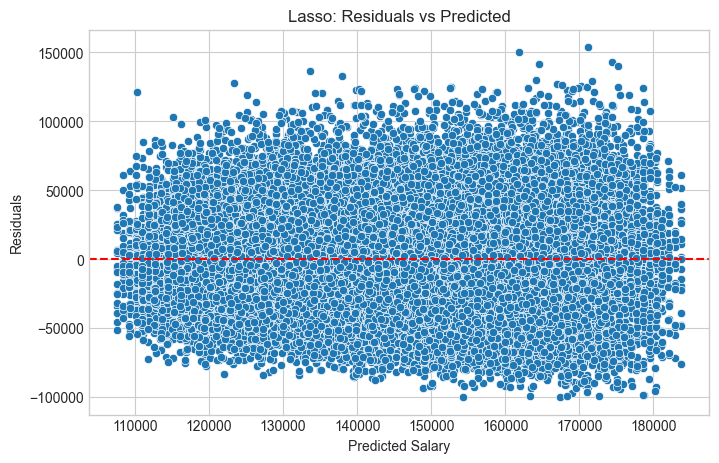

Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\figures\model_diagnostics-residual_distribution.png


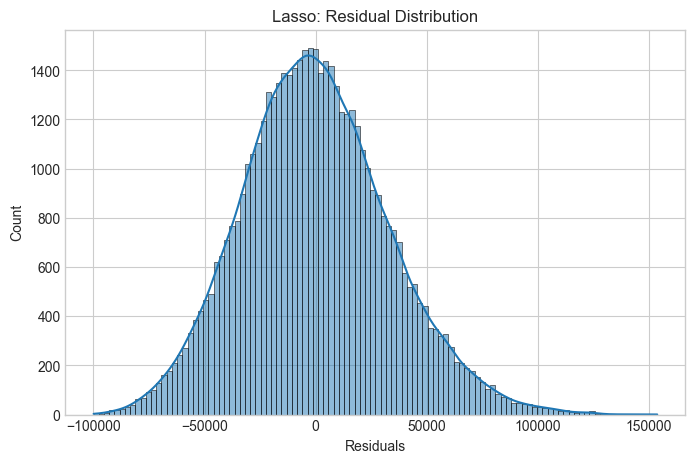

Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\figures\model_diagnostics-normal_qq_plot.png


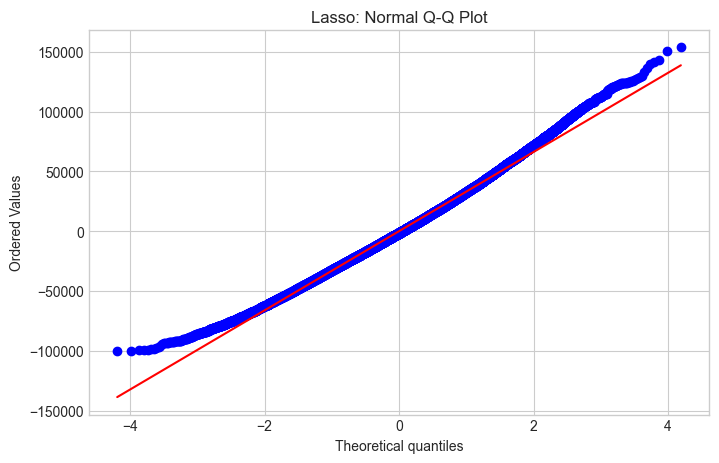

Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\figures\model_diagnostics-residuals_vs_actual.png


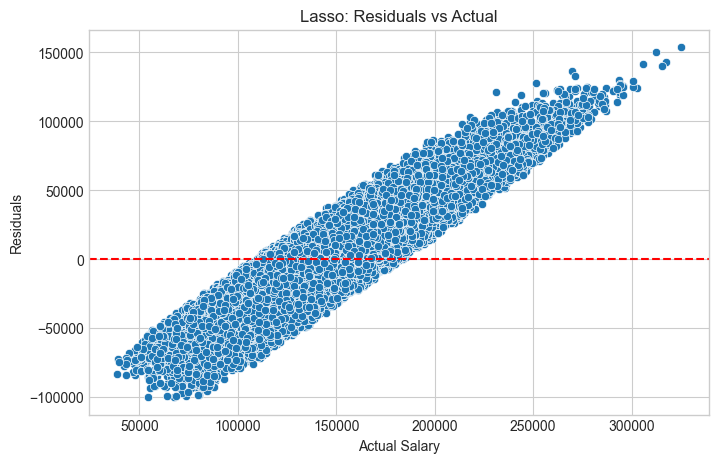

Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\figures\model_diagnostics-actual_vs_predicted.png


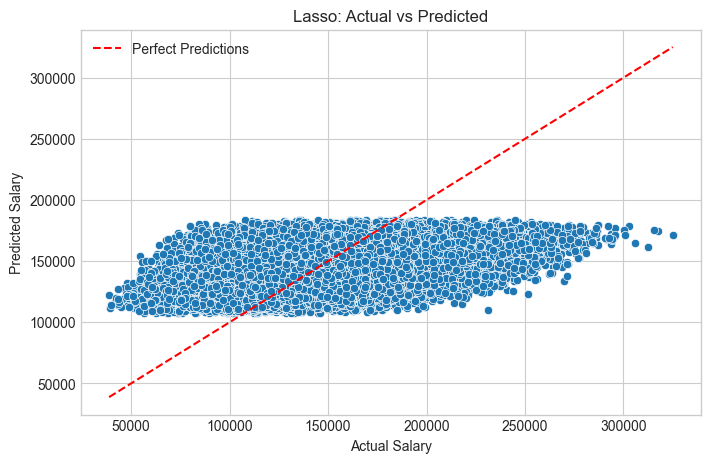

In [170]:
def diagnose_regression_model(
    best_model,
    best_model_result,
    X_test,
    y_test,
    model_config
):
    """
    Generates diagnostic statistics and plots for the selected regression model using test data. 
    
    Calculates predictions and residuals, displays and saves residual summary statistics, 
    and generates only the diagnostic plots specified in the model configuration to evaluate prediction accuracy, 
    residual distribution, normality, and error patterns. 
    
    Returns a DataFrame containing actual values, predicted values, and residuals.
    """
    # 1. Identify the selected model.
    model_name = best_model_result["Model"]

    # 2. Retrieve its diagnostic configuration.
    diagnostics = model_config[model_name]["model_diagnostics"]

    # 3. Generate predictions and calculate residuals.
    y_pred = best_model.predict(X_test)

    y_actual = pd.Series(y_test).reset_index(drop=True)
    y_pred = pd.Series(y_pred).reset_index(drop=True)
    residuals = y_actual - y_pred

    # 4. Prepare diagnostic data.
    diagnostic_df = pd.DataFrame({
        "Actual": y_actual,
        "Predicted": y_pred,
        "Residuals": residuals
    })

    save_table(table=diagnostic_df["Residuals"].describe().to_frame(), filename="model_diagnostics-best_model_diagnostics", index=True)

    print(f"MODEL DIAGNOSTICS: {model_name}")
    print("\nResidual Summary Statistics")
    display(diagnostic_df["Residuals"].describe().to_frame())

    # 5. Generate only the configured diagnostics.
    for diagnostic in diagnostics:

        if diagnostic == "residuals_vs_predicted":
            fig = plt.figure(figsize=(8, 5))
            sns.scatterplot(
                x=diagnostic_df["Predicted"],
                y=diagnostic_df["Residuals"]
            )
            plt.axhline(0, color="red", linestyle="--")
            plt.title(f"{model_name}: Residuals vs Predicted")
            plt.xlabel(f"Predicted {TARGET_COLUMN_NAME['feature']}")
            plt.ylabel("Residuals")
            save_figure(filename="model_diagnostics-residuals_vs_predicted", fig=fig)
            plt.show()

        elif diagnostic == "residual_distribution":
            fig = plt.figure(figsize=(8, 5))
            sns.histplot(
                diagnostic_df["Residuals"],
                kde=True
            )
            plt.title(f"{model_name}: Residual Distribution")
            plt.xlabel("Residuals")
            save_figure(filename="model_diagnostics-residual_distribution", fig=fig)
            plt.show()

        elif diagnostic == "normal_qq_plot":
            fig = plt.figure(figsize=(8, 5))
            stats.probplot(
                diagnostic_df["Residuals"],
                dist="norm",
                plot=plt
            )
            plt.title(f"{model_name}: Normal Q-Q Plot")
            save_figure(filename="model_diagnostics-normal_qq_plot", fig=fig)
            plt.show()

        elif diagnostic == "residuals_vs_actual":
            fig = plt.figure(figsize=(8, 5))
            sns.scatterplot(
                x=diagnostic_df["Actual"],
                y=diagnostic_df["Residuals"]
            )
            plt.axhline(0, color="red", linestyle="--")
            plt.title(f"{model_name}: Residuals vs Actual")
            plt.xlabel(f"Actual {TARGET_COLUMN_NAME['feature']}")
            plt.ylabel("Residuals")
            save_figure(filename="model_diagnostics-residuals_vs_actual", fig=fig)
            plt.show()

        elif diagnostic == "actual_vs_predicted":
            fig, ax = plt.subplots(figsize=(8, 5))

            sns.scatterplot(
                x=diagnostic_df["Actual"],
                y=diagnostic_df["Predicted"],
                ax=ax
            )

            # Perfect prediction reference line.
            min_value = min(
                diagnostic_df["Actual"].min(),
                diagnostic_df["Predicted"].min()
            )
            max_value = max(
                diagnostic_df["Actual"].max(),
                diagnostic_df["Predicted"].max()
            )

            ax.plot(
                [min_value, max_value],
                [min_value, max_value],
                color="red",
                linestyle="--",
                label="Perfect Predictions"
            )

            ax.set_title(f"{model_name}: Actual vs Predicted")
            ax.set_xlabel(f"Actual {TARGET_COLUMN_NAME['feature']}")
            ax.set_ylabel(f"Predicted {TARGET_COLUMN_NAME['feature']}")
            ax.legend()

            save_figure(
                filename="model_diagnostics-actual_vs_predicted",
                fig=fig
            )

            plt.show()

        else:
            print(f"Unrecognized diagnostic skipped: {diagnostic}")

    return diagnostic_df


# ============================================================
# EXECUTE MODEL DIAGNOSTICS
# ============================================================

best_model_diagnostics = diagnose_regression_model(
    best_model=best_model,
    best_model_result=best_model_result,
    X_test=X_test,
    y_test=y_test,
    model_config=REGRESSION_MODEL_CONFIG
)

## Model Interpretation

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\tables\model_interpretation-feature_importance.csv
FEATURE IMPORTANCE: Lasso


,Feature,Importance,Importance Std
0,experience_years,7047.062649,55.087946
1,skills_count,659.878424,20.492761
2,certifications,222.716405,13.269848
3,job_title,0.000000,0.000000
4,education_level,0.000000,0.000000
5,industry,0.000000,0.000000
6,company_size,0.000000,0.000000
7,location,0.000000,0.000000
8,remote_work,0.000000,0.000000


Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\outputs\figures\model_interpretation-permutation_feature_importance.png


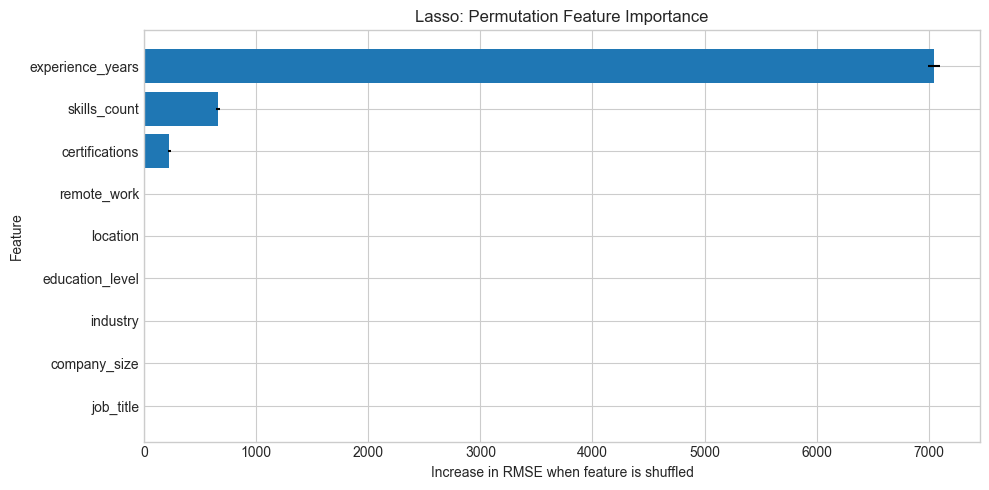

Interpretation: Larger positive importance means shuffling that feature worsened RMSE more, suggesting the model relies more on it. This indicates predictive usefulness, not causation. Because your test set has already been used for model comparison, treat these importance results as exploratory.


In [171]:
def interpret_regression_model(
    best_model,
    best_model_result,
    X_test,
    y_test,
    random_state=RANDOM_STATE
):
    """
    Calculates and ranks feature importance for the selected regression model
    using permutation importance on the test data.

    Displays and saves a feature importance table containing mean importance
    and standard deviation.

    Generates and saves a bar chart of the top 20 most influential features.

    Returns the sorted feature importance DataFrame.
    """
    # 1. Identify the selected model.
    model_name = best_model_result["Model"]

    # 2. Calculate permutation importance.
    importance = permutation_importance(
        estimator=best_model,
        X=X_test,
        y=y_test,
        scoring="neg_root_mean_squared_error",
        n_repeats=10,
        random_state=random_state,
        n_jobs=-1
    )

    # 3. Build and sort the importance table.
    feature_names = (
        X_test.columns
        if hasattr(X_test, "columns")
        else [f"Feature {i}" for i in range(X_test.shape[1])]
    )

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance.importances_mean,
        "Importance Std": importance.importances_std
    }).sort_values(
        by="Importance",
        ascending=False
    ).reset_index(drop=True)

    save_table(table=importance_df, filename="model_interpretation-feature_importance")

    print(f"FEATURE IMPORTANCE: {model_name}")
    display(importance_df)

    # 4. Plot the most influential features.
    plot_df = importance_df.head(20).sort_values(
        by="Importance",
        ascending=True
    )

    fig = plt.figure(figsize=(10, max(5, len(plot_df) * 0.35)))
    plt.barh(
        plot_df["Feature"],
        plot_df["Importance"],
        xerr=plot_df["Importance Std"]
    )
    plt.title(f"{model_name}: Permutation Feature Importance")
    plt.xlabel("Increase in RMSE when feature is shuffled")
    plt.ylabel("Feature")
    plt.tight_layout()
    save_figure(filename="model_interpretation-permutation_feature_importance", fig=fig)
    plt.show()

    return importance_df


# ============================================================
# EXECUTE MODEL INTERPRETATION
# ============================================================

best_model_feature_importance = interpret_regression_model(
    best_model=best_model,
    best_model_result=best_model_result,
    X_test=X_test,
    y_test=y_test
)

print("Interpretation: Larger positive importance means shuffling that feature worsened RMSE more, suggesting the model relies more on it. This indicates predictive usefulness, not causation. Because your test set has already been used for model comparison, treat these importance results as exploratory.")

## Save Model

In [172]:
def save_best_regression_model(
    best_model,
    best_model_result
):
    model_name = best_model_result["Model"]

    # Ensure the model directory exists.
    MODEL_DIR.mkdir(parents=True, exist_ok=True)

    # Create the model file path dynamically.
    filename = model_name.lower().replace(" ", "_") + ".joblib"
    model_path = MODEL_DIR / filename

    # Save the fitted pipeline.
    joblib.dump(best_model, model_path)
    # joblib.dump(best_model, alt_model_path)

    print(f"Best Model: {model_name}")
    print(f"Saved Model Path: {model_path}")

    return model_path


# ============================================================
# EXECUTE
# ============================================================

best_model_path = save_best_regression_model(
    best_model=best_model,
    best_model_result=best_model_result
)

Best Model: Lasso
Saved Model Path: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\models\lasso.joblib


## Test Saved Model

In [173]:
def load_and_test_saved_model(
    best_model_path,
    X_test,
    y_test
):
    # 1. Load the saved fitted pipeline.
    loaded_model = joblib.load(best_model_path)

    # 2. Generate predictions without retraining.
    predictions = loaded_model.predict(X_test)

    # 3. Compare actual and predicted values.
    prediction_results = pd.DataFrame({
        f"Actual {TARGET_COLUMN_NAME['feature']}": y_test,
        f"Predicted {TARGET_COLUMN_NAME['feature']}": predictions
    }).reset_index(drop=True)

    prediction_results["Error"] = (
        prediction_results[f"Actual {TARGET_COLUMN_NAME['feature']}"]
        - prediction_results[f"Predicted {TARGET_COLUMN_NAME['feature']}"]
    )

    save_data(data=prediction_results, filename="model_prediction-saved_model_predictions")
    print("SAVED MODEL PREDICTION CHECK")
    display(prediction_results)

    return loaded_model, prediction_results


# ============================================================
# EXECUTE
# ============================================================

loaded_best_model, saved_model_predictions = load_and_test_saved_model(
    best_model_path=best_model_path,
    X_test=X_test,
    y_test=y_test
)

Data saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\employee-salary-prediction\data\processed\model_prediction-saved_model_predictions.csv
SAVED MODEL PREDICTION CHECK


,Actual Salary,Predicted Salary,Error
0,164009,146569.805890,17439.194110
1,79594,138664.943541,-59070.943541
2,74090,142995.083625,-68905.083625
3,177193,142004.103816,35188.896184
4,120012,128736.279656,-8724.279656
...,...,...,...
49995,136275,148310.933038,-12035.933038
49996,168515,150336.491401,18178.508599
49997,176232,158513.349799,17718.650201
49998,152933,162278.278483,-9345.278483


## New Data Prediction

In [174]:
def predict_employee_salary_price(loaded_model, new_data):
    # Ensure input is a DataFrame.
    if not isinstance(new_data, pd.DataFrame):
        new_data = pd.DataFrame(new_data)

    # Generate predictions using the saved fitted pipeline.
    predictions = loaded_model.predict(new_data)

    # Return predictions in a structured DataFrame.
    prediction_results = pd.DataFrame({
        f"Predicted {TARGET_COLUMN_NAME['feature']}": predictions
    })

    print(f"{TARGET_COLUMN_NAME['label'].upper()} PREDICTIONS")
    display(prediction_results)

    return prediction_results


# ============================================================
# USAGE
# ============================================================

# Replace this with new salary data containing the same
# input features used when training the model.
#"
# new_salary_data = pd.DataFrame([{...}])
#
# new_salary_predictions = predict_employee_salary_price(
#     loaded_model=loaded_best_model,
#     new_data=new_salary_data
# )